# 사전 과제

<aside>

강의자료를 예습하고 마크다운으로 정리해주세요!

---

- CNN
    - 픽셀, 채널, 색공간(Grayscale, RGB, HSV)의 개념
    - CNN의 개념과 구조
- MLP vs. CNN
    - MLP의 한계와 CNN
- 합성곱(Convolution)과 풀링(Pooling)
    - Convolution layer
    - Padding
    - Stride
    - Pooling
- 이미지 딥러닝 응용
    - 이미지 분류(Image Classification)
    - 객체 탐지(Object Detection)
    - 이미지 캡셔닝(Image Captioning)
- 순차 데이터
    - 정형 데이터 vs. 순차 데이터
- RNN
    - RNN의 구조와 원리
    - RNN 아키텍쳐 종류와 활용 예시
    - RNN 한계점
- LSTM&GRU
    - LSTM의 구조와 원리
    - GRU의 구조와 원리
    - 상황별 모델 선택
- Seq2Seq
    - Seq2Seq의 구조와 원리
    - Seq2Seq의 한계
</aside>

# **딥러닝 1. FOCUS ON IMAGE + SEQUENCE**
## **1. 합성곱 신경망(CNN, Convolutional NN)**

### **0. 픽셀과 채널**

- 픽셀 : 이미지 데이터를 구성하는 가장 기본적인 단위
- 하나의 픽셀은 이미지의 특정 위치에 해당하는 색상 또는 밝기 정보를 가지고 있음


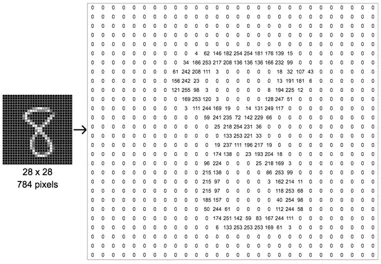
- 이미지 크기
    - 흑백 : 일반적으로 이미지 데이터의 기본단위인 2차원배열(NumPy ndarray) = (세로 픽셀 수 x 가로 픽셀 수)로 표현

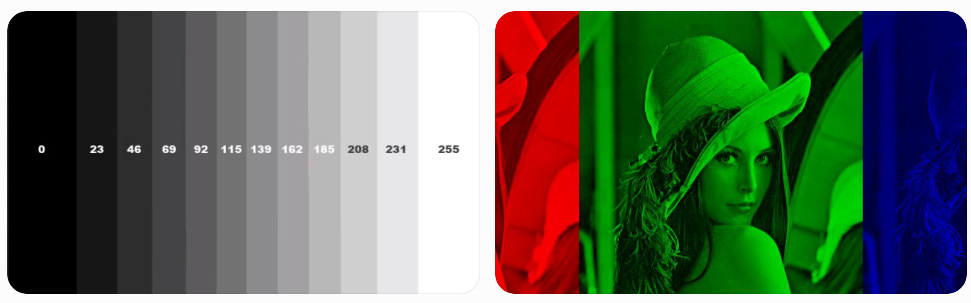
- 픽셀 값 : 이미지의 색상이나 밝기를 숫자로 표현한 값   
    - **흑백(Grayscale) 이미지** : 하나의 픽셀 값으로 밝기를 표현. 일반적으로 0 ~ 255 값 사용. 0은 검은색, 255는 흰색이고, 그 사이 값은 밝기에 따른 다양한 회색으로 표현.
    - **컬러(RGB) 이미지** : 하나의 픽셀을 Red(빨강), Green(초록), Blue(파랑) 세 가지 색상 값으로 표현. 각 채널은 0 ~ 255 값 가지며, 세 값의 조합으로 하나의 색상이 만들어짐.

#### **채널**
- 이미지의 색상 정보를 구성하는 각각의 데이터 층을 의미
- 하나의 이미지에서 색상이나 밝기 정보를 구분하여 저장하는 단위

#### **색공간**
- 이미지를 구성하는 색상을 숫자로 표현하는 방법이나 체계
- 이미지의 색상 정보를 어떤 기준으로 표현하느냐에 따라 다양한 색공간 존재

- **그레이 스케일(Grayscale)**
    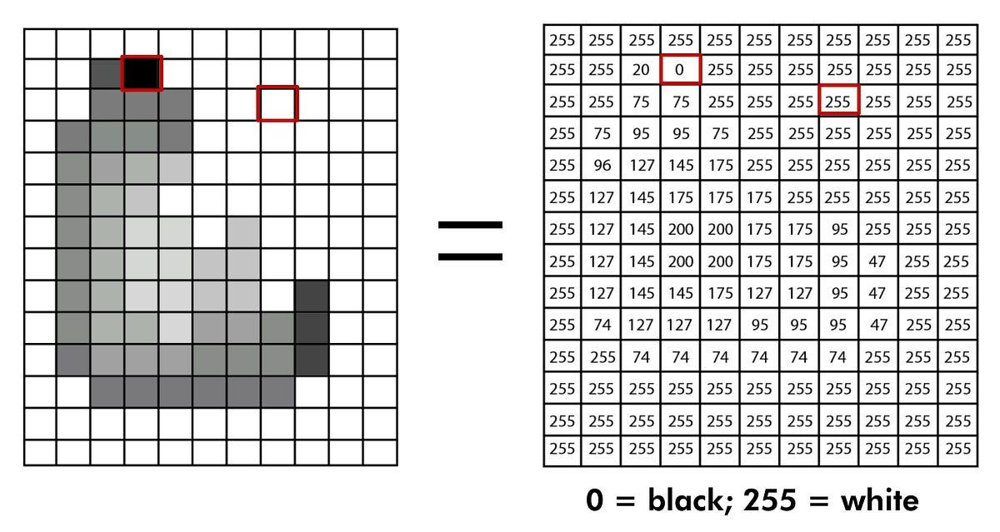
    - 이미지의 색상 정보 없이 픽셀의 밝기만을 이용해 표현하는 방식
    - **특징**
        - 각 픽셀은 하나의 채널 값으로 표현되며, 일반적으로 0~255 범위의 명도 값을 사용. 예를 들어 0은 검은색, 128은 중간 정도의 회색, 255는 흰색을 의미
        - 채널 값이 1인 이유는 빨강, 초록, 파랑과 같은 여러 색상 성분을 구분할 필요 없이 하나의 밝기 정보만 저장하면 되기 때문

    - **저장 방법**
        - 흑백 이미지이므로 채널 수가 1임을 고려하면 (28 × 28 × 1)의 크기를 가지는 3차원 텐서로 표현가능. 다만 NumPy에서는 채널 차원을 생략하여 일반적으로 (28 × 28)의 2차원 배열로 저장하기도 함

    - **흑백 이미지의 채널 수가 1인 이유?**
        - **각 픽셀이 표현하는 정보가 '오직 하나의 값(밝기, 명도)'이기 때문**. 컬러 이미지와 비교하여 이해하기!!
        - **컬러 이미지 (RGB):** 사람의 눈이 인식하는 다채로운 색상을 표현하기 위해 빨간색(Red), 초록색(Green), 파란색(Blue)의 3가지 색상 성분(채널)이 각각 필요! 
        - **흑백 이미지 (Grayscale):** 색상 정보는 제외하고 오직 빛의 세기(어둡고 밝은 정도)만 표현하면 되기 때문에 **1개의 채널**만 있으면 충분!
    
    - **텐서란?**
        - 텐서는 수학과 프로그래밍(특히 딥러닝)에서 다차원 데이터 배열(Multi-dimensional Array)을 통칭하는 용어. 쉽게 말해, **스칼라(Scalar), 벡터(Vector), 행렬(Matrix)을 모두 아우르는 더 포괄적인 개념**
        - 텐서는 데이터가 몇 개의 축(Axis 또는 Dimension)을 가지느냐에 따라 차원이 결정됩니다.
            - **0차원 텐서 (스칼라, Scalar):** 하나의 숫자
                - *예시:*  3.14
            - **1차원 텐서 (벡터, Vector):** 숫자가 일렬로 나열된 형태 (축 1개)
                - *예시:*  [1.0, 2.5, 3.1]
            - **2차원 텐서 (행렬, Matrix):** 행과 열로 이루어진 2차원 표 형태 (축 2개)
                - *예시:*  앞서 살펴본 (28 x 28) 크기의 흑백 이미지 배열
            - **3차원 이상 텐서 (Tensor):** 행렬이 여러 개 쌓이거나, 채널·배치(Batch) 등의 추가 축이 포함된 다차원 구조
                - *예시:* (28 x 28 x 1) = 흑백 이미지 텐서 / (28 x 28x 3)  = RGB 컬러 이미지 텐서 

- **RGB**
    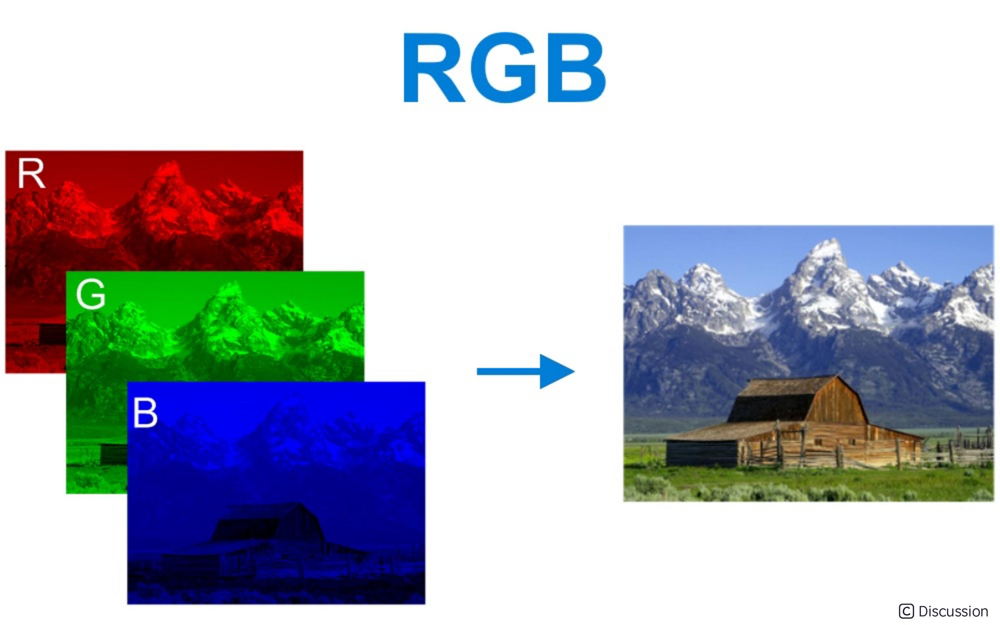
    - Red(빨강), Green(초록), Blue(파랑) 세 가지 색상을 조합하여 하나의 색을 표현하는 색공간
    - **특징**
        - 하나의 픽셀은 세 가지 색깔, 삼원색의 조합으로 이루어짐. 예를 들어 빨강과 초록의 값이 높고 파랑의 값이 낮으면 노란색 계열로 표현할 수 있음. **세 가지 채널의 값이 합쳐져 최종적인 하나의 색상을 만들어내는 원리**이므로, **채널 값은 3**으로 표현!
    - **저장방법**
        - 높이가 28, 너비가 28인 컬러 이미지가 있다면 이 이미지의 텐서는 (28 × 28 × 3)의 크기를 가지는 3차원 텐서! 채널은 때로는 깊이(depth)라고도 함.        

### **1. CNN의 개념**
- **CNN이 필요하게 된 배경 : 이미지 인식 방법 차이!**
    1. **사람이 이미지를 인식하는 방법**
    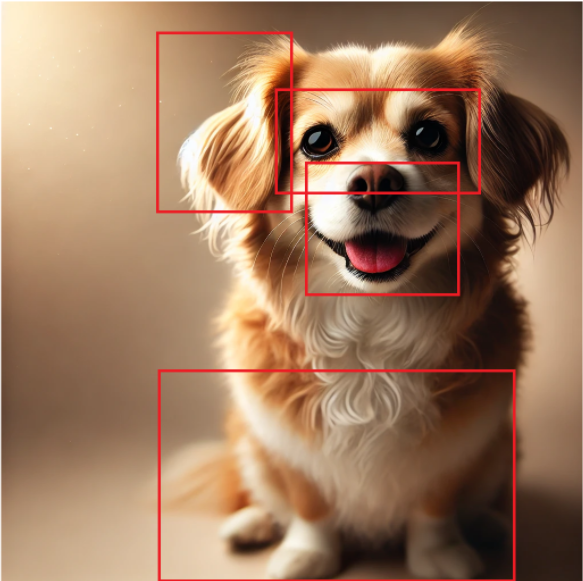
    - 컴퓨터와 달리 사람은 이미지를 구성하는 모든 픽셀을 하나하나 살펴보면서 물체를 인식하지 않는다!

    - 예를 들어, 강아지 사진을 볼 때는 눈, 귀, 코, 꼬리처럼 물체를 구분하는 데 중요한 영역과 특징에 집중!

    - 이러한 특징들을 종합하여 이미지에 어떤 물체가 있는지 판단, 각 부분이 어떤 관계를 가지는지도 파악!

    2. **컴퓨터가 이미지를 인식하는 방법**
    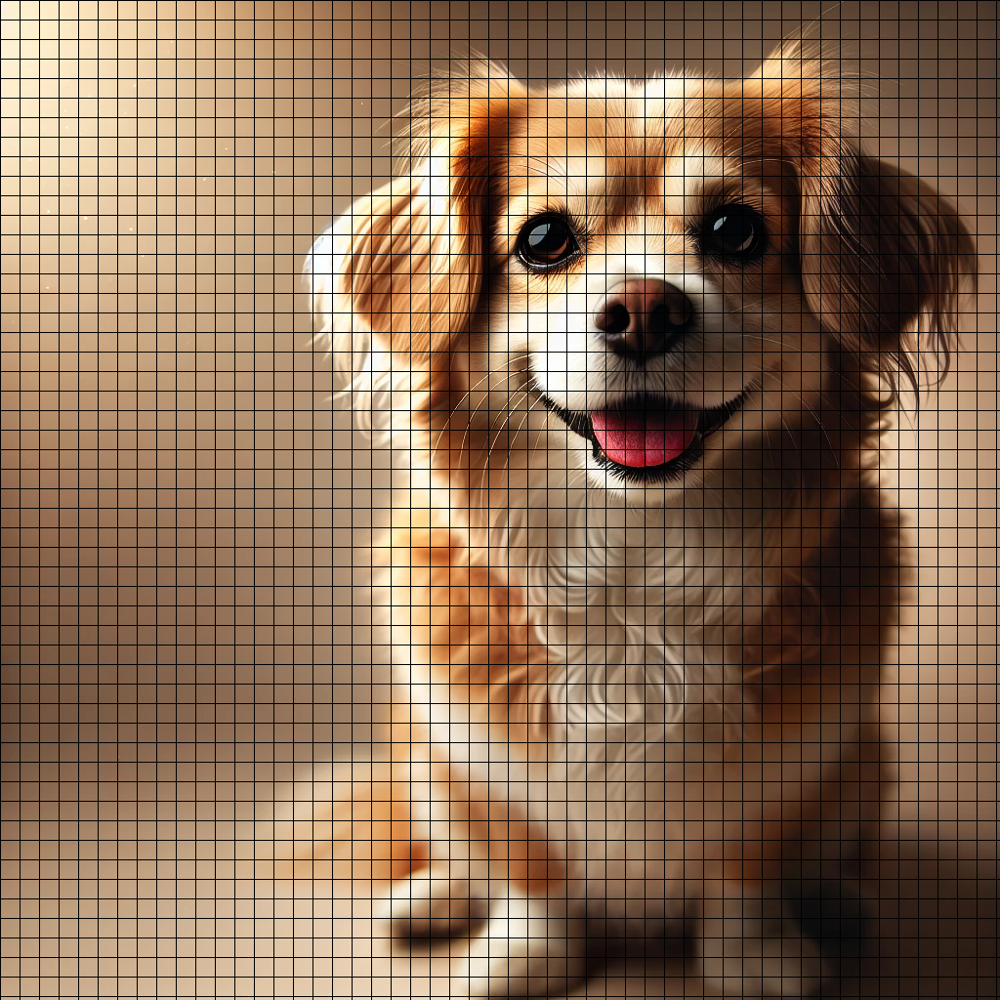
    - 컴퓨터는 이미지를 작은 픽셀 단위로 구분, 각 픽셀에 저장된 색상과 밝기 등의 숫자 정보를 처리.

    - 컴퓨터에게 이미지는 하나의 강아지 사진이 아닌 **수많은 픽셀 값이 모여 만들어진 숫자 데이터!**

- **픽셀 정보를 그냥 학습하면 생기는 문제접**
    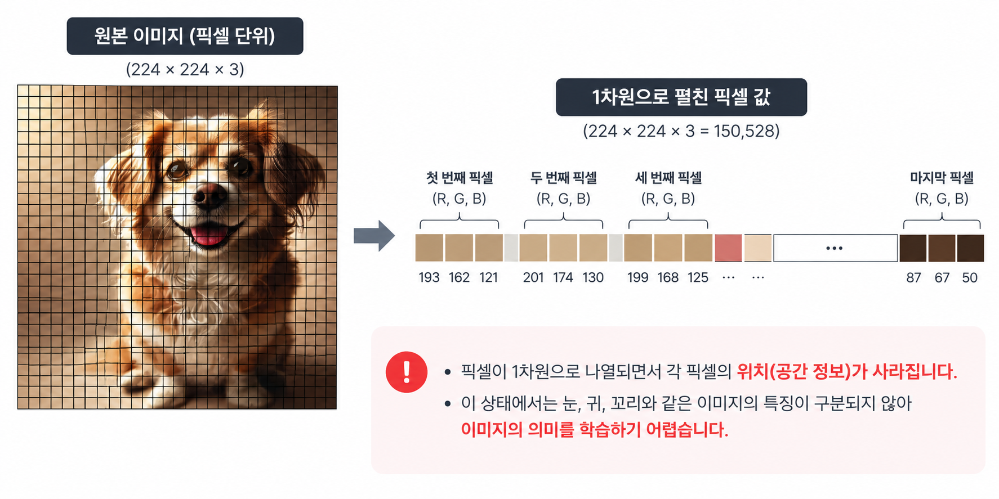
    - 이미지를 단순히 1차원 배열로 펼쳐서 학습하면 원래 이미지가 가지고 있던 2차원 공간 구조가 명확하게 활용되지 않는다!

    - 픽셀의 배열 순서 자체가 무작위로 바뀌는 것은 아니지만, 서로 가까이 있는 픽셀들이 어떤 관계를 갖는 지에 대한 정보가 모델에 직접적으로 반영되지 않기 때문

    - 이로 인해 눈, 귀, 꼬리처럼 주변 픽셀들이 모여 만들어지는 이미지의 특징을 학습하기 어려워짐!

- **MLP와 CNN의 구조 비교**
    - **MLP = FC Layer + ... + FC Layer**

    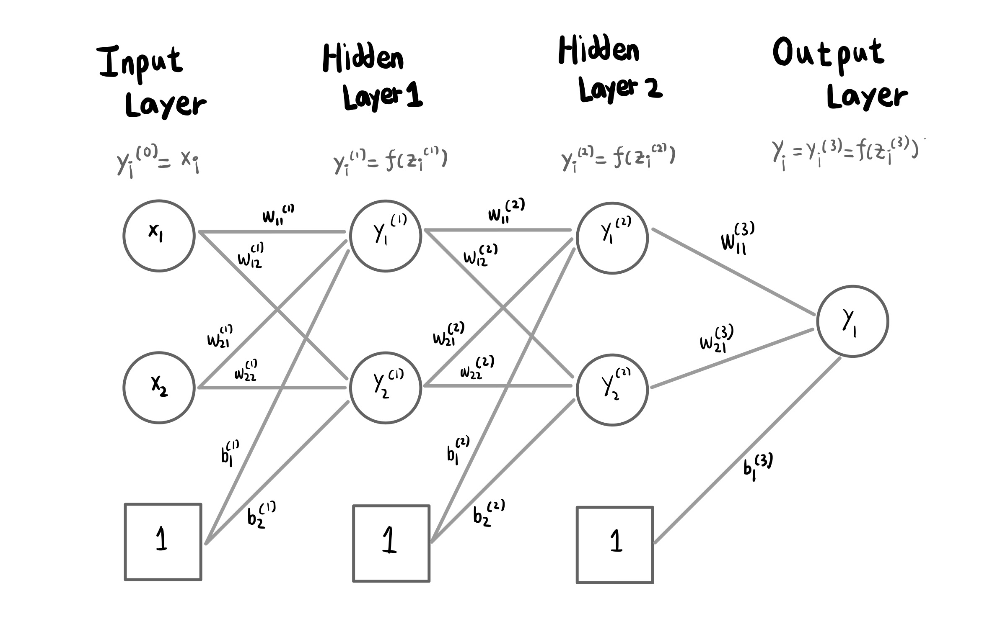
    
    - 입력된 데이터를 FC Layer에 전달하여 학습하는 구조. 이미지 데이터를 입력할 때는 일반적으로 2차원 이미지를 1차원 배열로 펼친 뒤 사용

    - **CNN = (Conv + Pool) + ... + Flatten + FC Layer + ... + FC Layer**
    
    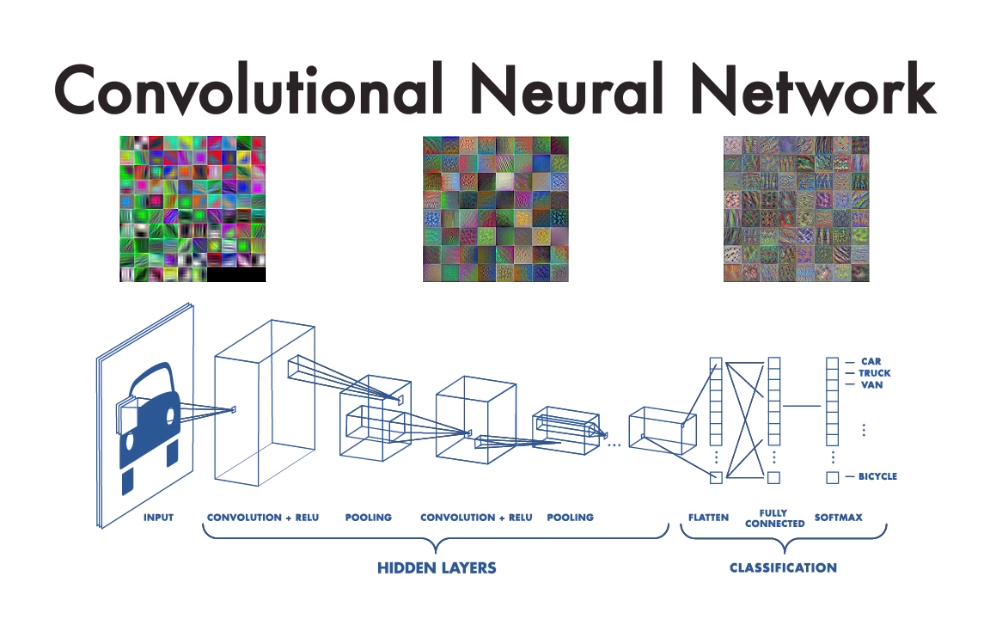
    
    - 이미지의 공간적 특징을 유지하며 Conv와 Pool을 반복하여 이미지 특징 추출. 이후 Flatten을 통해 추출된 특징을 1차원으로 변환, FC Layer를 적용하여 이미지 분류

    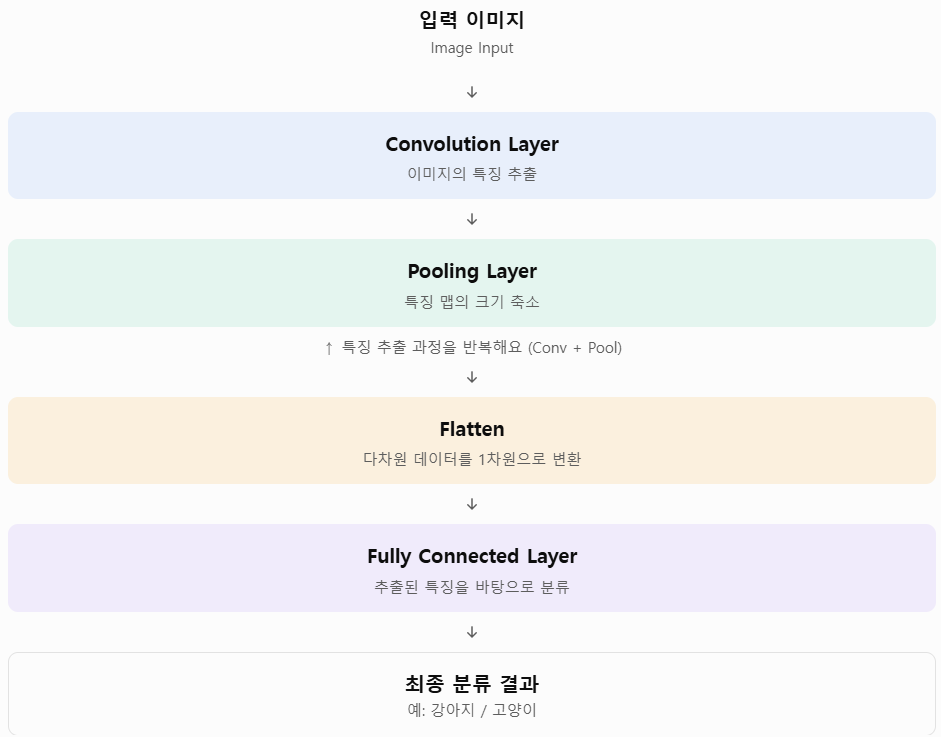
    - **특징 추출 (Feature Learning)** (이미지의 특징을 학습)
        - Convolution Layer

            필터(Kernel)를 이미지 위에서 이동시키며 모서리, 질감, 형태 등 이미지의 다양한 특징을 추출
        - Pooling Layer

            추출된 특징 맵의 크기를 줄이고 중요한 특징을 유지하여 연산량을 감소시킴
    - **Flatten**

        여러 차원으로 이루어진 특징 맵을 FC Layer에 입력할 수 있도록 1차원 배열로 변환
    - **분류 (Classification)** (학습한 특징을 바탕으로 어떤 이미지인지 분류)
        - Fully Connected Layer

            추출된 특징들을 종합하여 이미지가 어떤 클래스에 속하는지 최종적으로 분류

    - **가장 큰 차이점** : CNN이 FC Layer를 적용하기 전 Conv 와 Pool을 이용해 이미지의 특징을 학습하는 과정이 추가된다!


### **2. 왜 이미지 처리에 MLP가 아닌 CNN을 사용할까?**
#### **1. 이미지 데이터의 구조**
1. **흑백(grayscale) 이미지의 구조**
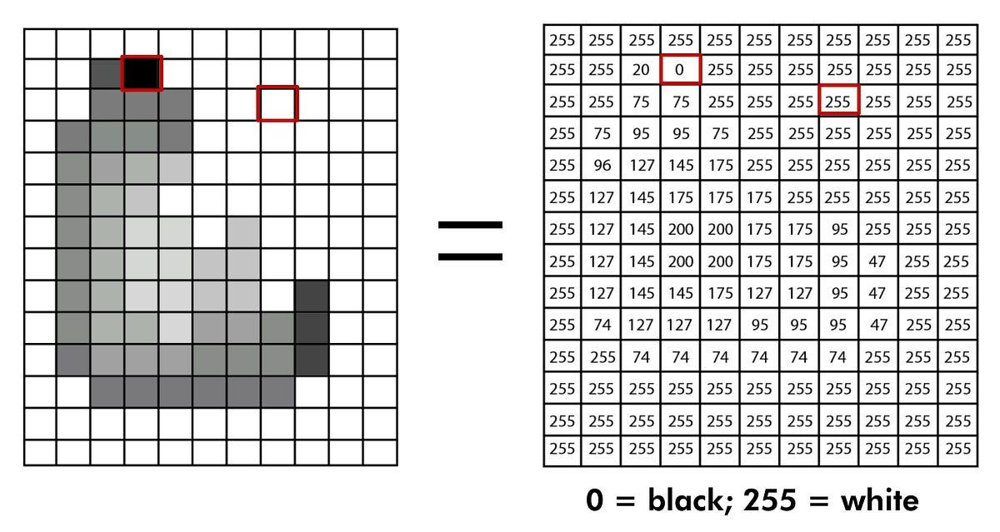

**흑백 이미지는 각 픽셀에 하나의 밝기 값을 저장하는 방식.** 

일반적으로 픽셀 값은 0~255 범위로 표현.(**0은 검은색,** **255는 흰색**)

**흑백 이미지**는 각 픽셀에 하나의 값(0~255)만 존재하므로 **H × W 형태의 2차원 배열**로 표현할 수 있음!
- **H x W**
    - H (Height): 이미지의 높이 → 세로 픽셀 수
    - W (Width): 이미지의 너비 → 가로 픽셀 수

2. **컬러(RGB) 이미지의 구조**
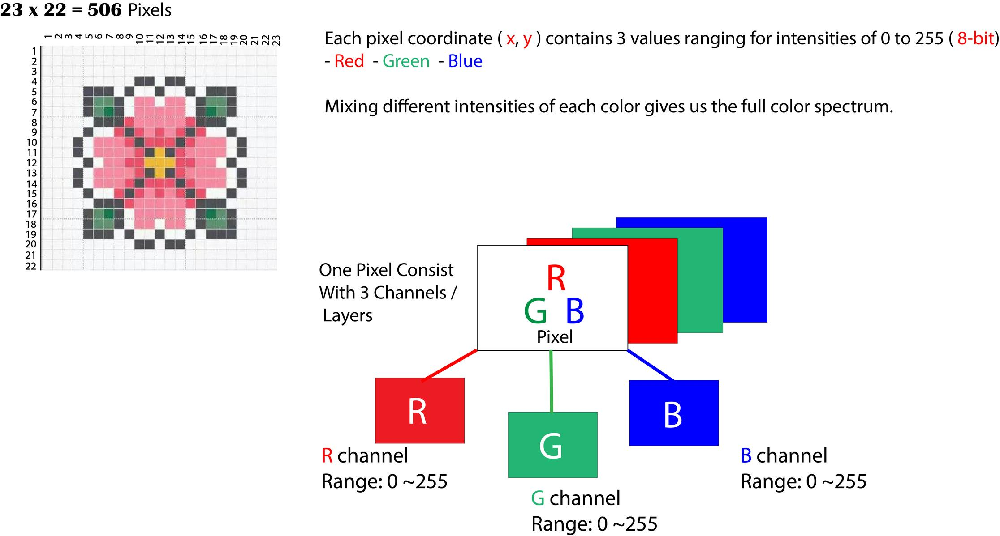
**RGB 이미지는 하나의 픽셀을 Red(빨강), Green(초록), Blue(파랑) 세 가지 색상 값으로 구성.**

각 채널은 일반적으로 0~255 범위의 값을 가지고, 세 값의 조합으로 하나의 색상이 만들어짐

**컬러 이미지**는 각 픽셀마다 3개의 색상 값이 존재하므로 (**H × W × 3) 형태의 3차원 배열**로 표현할 수 있음!

3. **대표적인 이미지 데이터셋**
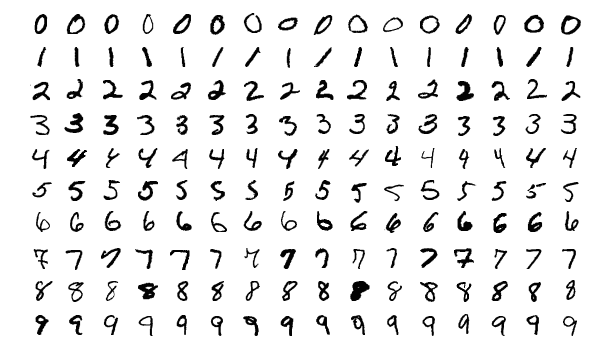
손글씨 숫자 이미지로 구성된 **MNIST**는 0부터 9까지의 숫자를 담은 (28 x 28) 크기의 흑백 이미지 데이터셋으로, 이미지 분류와 CNN 학습의 기초 예제로 자주 활용

4. **이미지 구조를 유지하는 모델이 필요한 이유!**
일반적인 정형 데이터 : 각 열에 독립적인 의미를 가진 값들이 나열된 형태

**반면 이미지: 픽셀들이 가로와 세로 방향으로 연결되어 있으며, 주변 픽셀 간의 관계와 위치 정보가 중요!**

따라서 이미지 데이터를 단순히 숫자 목록으로 처리하기보다는, **픽셀 간의 공간적 관계와 이미지의 구조를 유지하면서 특징을 학습할 수 있는 모델**이 필요! (대표적인 모델: CNN)


#### **2. MLP의 한계**
1. **위치, 크기, 회전 등의 변화에 취약 (Translation Variant)**
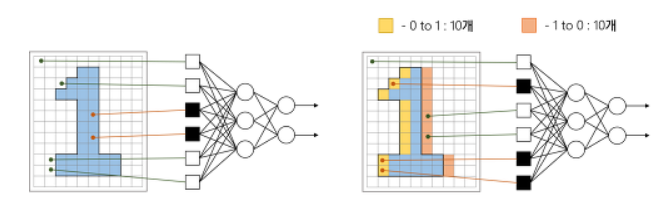

    MLP는 이미지를 1차원 배열로 펼쳐서 입력받고, 각 픽셀 위치에 대응하는 가중치를 학습. 따라서 숫자 1이 조금만 이동해도 기존에 값이 있던 픽셀 위치에는 0이 들어가고, 새로운 위치에 픽셀 값이 들어가면서 입력 데이터가 크게 달라지는 오류가 발생!

    즉, **학습 데이터에서 보지 못한 위치나 형태의 변화가 발생하면** 기존의 숫자로 인식하지 못할 가능성이 높아져 성능이 크게 저하된다!

    **CNN에서는?**

    CNN은 Convolution을 통해 이미지의 특정한 특징을 추출. 이때 동일한 필터를 이미지의 여러 위치에 반복해서 적용하기 때문에, 특징이 이미지의 어느 위치에 나타나더라도 동일한 필터로 탐지가능!

    이후 Pooling을 통해 특징 맵의 크기를 줄이는 과정을 통해 작은 위치 변화에도 비슷한 특징을 유지하도록 도와줌.

    따라서 CNN은 특정한 특징이 정확히 어느 픽셀 위치에 있는지만 보는 것이 아닌, **이미지 안에 해당 특징이 존재하는지를 효과적으로 학습**할 수 있다!

2. **파라미터 폭발 (Parameter Explosion)**    

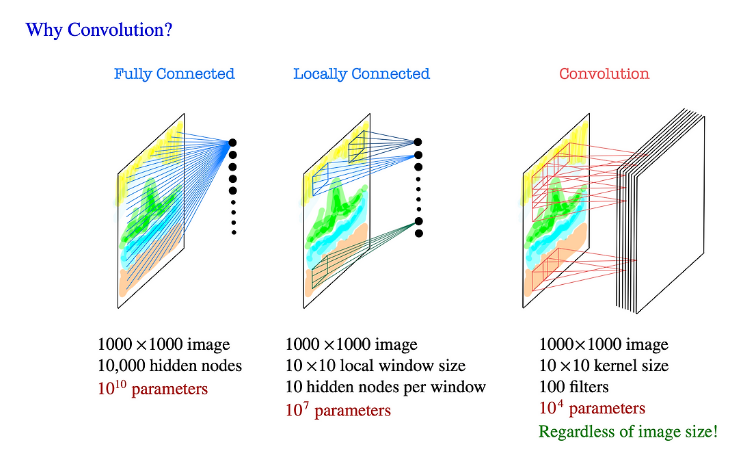

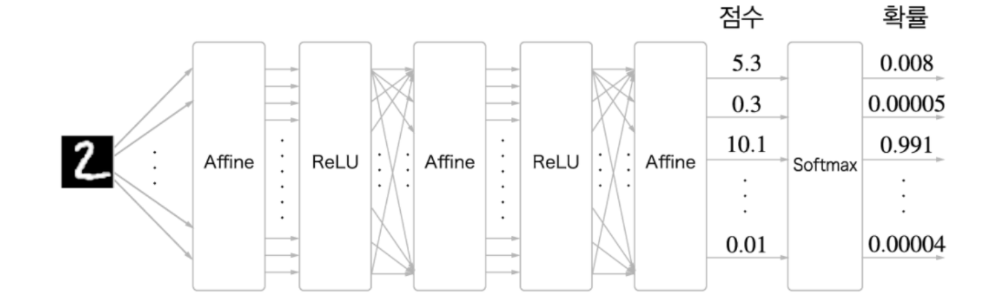
(완전연결 신경망을 이용한 이미지 입력 처리 구조)

MLP의 경우 완전연결(Fully connected) 구조로 인한 파라미터 급증이 이루어지며, 가중치 수가 이미지 픽셀의 개수만큼 생성

따라서 **과적합 가능성 상승, 이미지가 클수록 학습이 느리다**는 한계 존재

**완전연결(Fully connected) 구조란?**
- 신경망에서 **이전 레이어의 모든 노드(뉴런)가 다음 레이어의 모든 노드와 빠짐없이 연결되어 있는 구조**
- 덴스 레이어(Dense Layer)라고도 부름
- 특징
    - 입력 데이터의 모든 요소가 다음 층 모든 뉴런에 영향을 미침
    - 데이터 간의 복잡하고 비선형적 관계 학습에 매우 유리
    - 이미지를 1차원 벡터로 입력하기 떄문에, 이미지의 공간적 정보(픽셀 간의 위·아래·좌우 관계)가 사라지고 파라미터 급증이 이루어짐.

**CNN에서는?**

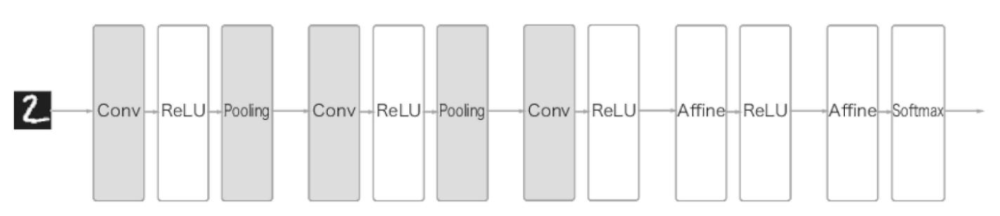

CNN은 이미지 전체의 픽셀을 다음 계층의 모든 노드에 연결하는 대신, 작은 영역에만 필터를 적용하는 **부분 연결 구조**를 사용. (예시: 3 × 3 필터는 한 번에 주변 9개 픽셀의 특징을 추출)

또한 동일한 필터의 가중치를 이미지의 여러 위치에서 공유하기 때문에, 이미지 전체를 처리하더라도 위치마다 새로운 가중치를 만들 필요 없음.

따라서 이미지 크기가 커지더라도 필터의 크기와 개수가 동일하다면 **파라미터 수는 크게 증가하지 않는다!**

**MLP와 CNN의 파라미터 수 비교 예시**

| 구분 | 구조 | 가중치 및 편향 수 |
| --- | --- | --- |
| MLP | 1,000,000개 입력 × 10,000개 노드 | 약 100억 개의 가중치 |
| CNN | 3 × 3 필터 32개 (흑백 이미지 기준) | 320개 |

3. **공간 정보 손실 (Loss of Spatial Info)**

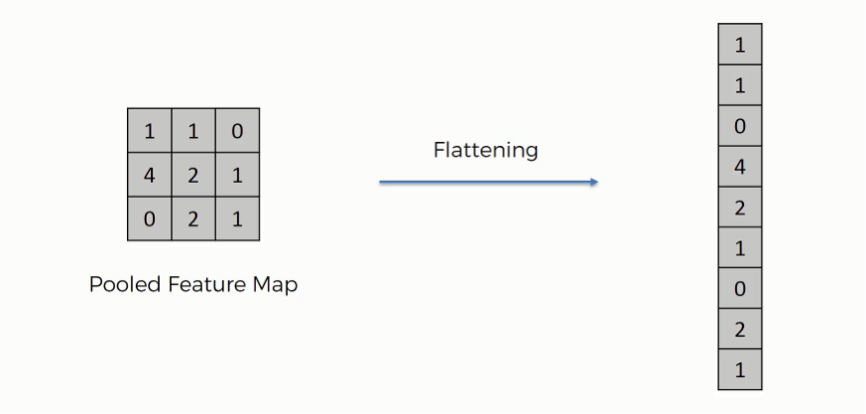

MLP는 이미지를 입력받을 때 2차원 또는 3차원으로 구성된 이미지 데이터를 1차원 벡터로 펼치는 Flatten 과정을 거침. (예시 : 28 × 28 크기의 흑백 이미지 -> 784개의 픽셀 값을 가진 1차원 배열로 변환)

이 과정에서 픽셀의 숫자 값 자체가 사라지는 것은 아니지만, 원래 이미지에서 어떤 픽셀들이 서로 가까이 있었는지에 대한 **2차원 공간 구조가 명시적으로 유지되지 않음.**

따라서 MLP는 **픽셀 간의 위치 관계나 주변 픽셀들이 모여 만들어내는 특징을 직접적으로 활용하기 어렵다**는 한계 존재.

**CNN에서는?**

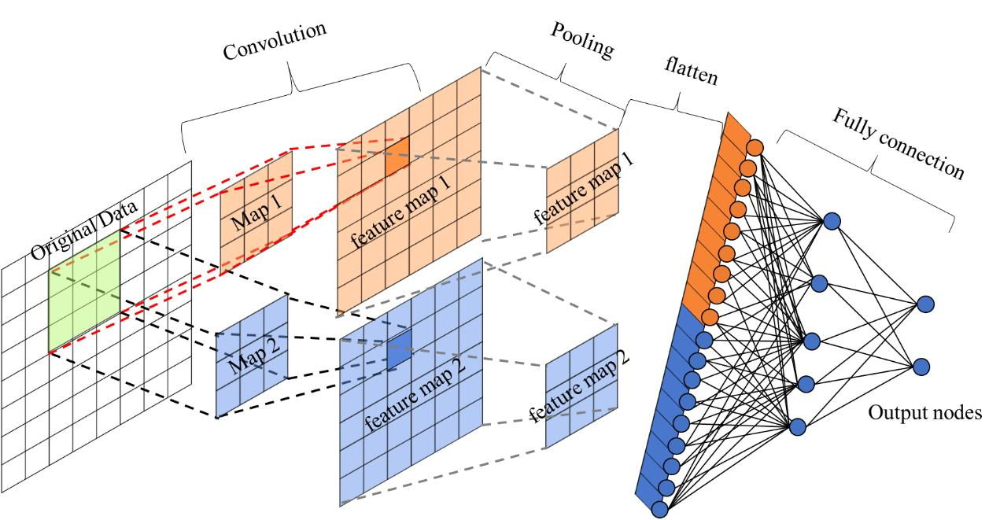

CNN은 이미지를 입력받을 때 처음부터 1차원으로 펼치지 않고, **H × W × C 형태의 다차원 구조**를 유지한 상태로 처리.

- Convolution Layer : 이미지의 작은 영역을 대상으로 연산하기 때문에 주변 픽셀 간의 관계와 위치 정보를 활용할 수 있음
- Pooling Layer : 특징 맵의 공간적 구조를 어느 정도 유지하면서 크기를 줄임
- 이후 여러 계층을 거쳐 이미지의 특징을 추출한 다음 Flatten을 적용해 1차원 벡터로 변환

즉, CNN은 이미지를 바로 Flatten하는 MLP와 달리, **이미지의 공간적 특징을 먼저 학습한 후 Flatten을 수행한다!**

따라서 **픽셀의 위치 관계와 주변 영역의 특징을 활용하는 데 유리**하고, 이미지 데이터를 효과적으로 학습할 수 있음.


### **3. 합성곱(Convolution)과 풀링(Pooling)**
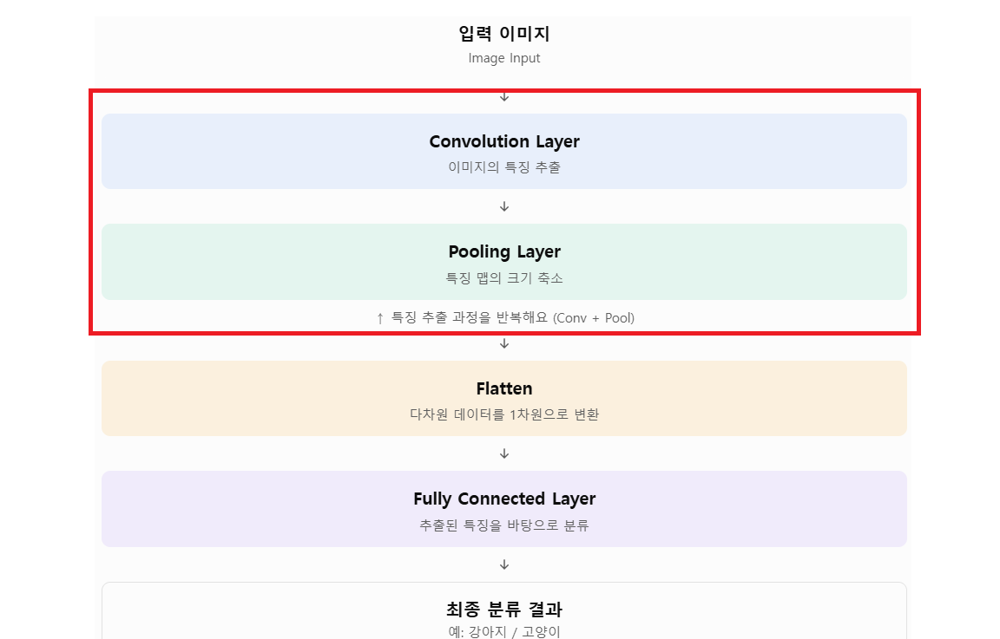

1. **convolution Layer**
- **개념**
    - **Convolution Layer**는 입력 이미지 전체를 일정한 크기의 필터(Filter)로 훑으면서 이미지의 특징을 추출하고 학습하는 계층

    - 입력 데이터에 필터(Filter)를 적용하여 연산을 수행하고, 그 결과를 새로운 데이터로 만들어 내는 과정 담당

    - 필터(Filter)는 수직선, 수평선, 모서리, 질감 등과 같은 이미지의 특정한 패턴이나 특징을 감지하는 역할

- **연산 과정**
    
    **① 필터가 이미지 위를 슬라이딩**

    - 작은 크기의 필터를 입력 이미지의 왼쪽 위에 배치
    - 이후 정해진 간격만큼 오른쪽으로 이동하면서 이미지의 각 영역을 차례대로 확인
    - 한 행의 연산이 끝나면 다음 행으로 이동하여 같은 과정을 반복

    **② 각 위치에서 요소별 곱셈 후 합계 계산**

    - 필터가 위치한 영역의 픽셀 값과 필터의 가중치를 각각 같은 위치끼리 곱함
    - 곱한 결과를 모두 더하여 하나의 숫자를 계산

    **③ 결과를 Feature Map에 저장**

    - 한 위치에서 계산된 결과값을 Feature Map의 해당 위치에 저장
    - 필터가 모든 위치에서 연산을 마치면 하나의 Feature Map이 완성

    - **필터(Filter)와 커널(Kernel)의 차이는?**
        - **필터(Filter)** : 여러 개의 커널(Kernel)이 모인 집합. 입력 데이터가 다채널(Channel)일 때 차이가 명확
        - **커널(Kernel)** : 이미지의 특정 패턴(선 모서리 등)을 추출하기 위해 사용하는 2차원 가중치 행렬(Matrix). 수학적인 연산이 실제로 일어나는 가장 기본 단위의 행렬

- **Feature Map**
    **정의**
    - Convolution 연산을 통해 생성되는 결과 데이터
    - 필터가 이미지의 여러 위치에서 계산한 결과값을 모아 하나의 Feature Map을 구성합니다.
    - 필터가 특정 특징에 반응할수록 해당 위치의 Feature Map 값이 커진다는 특징이 있습니다.

    **차원 결정 방식**

    - Feature Map의 개수는 사용하는 필터의 개수에 따라 결정됩니다.
    - 예를 들어 RGB 이미지에 3 × 5 × 5 크기의 필터 하나를 적용하면 Feature Map 하나가 생성됩니다. 여기서 앞의 3은 입력 채널 수, 5 × 5는 필터의 공간적 크기를 의미합니다.

    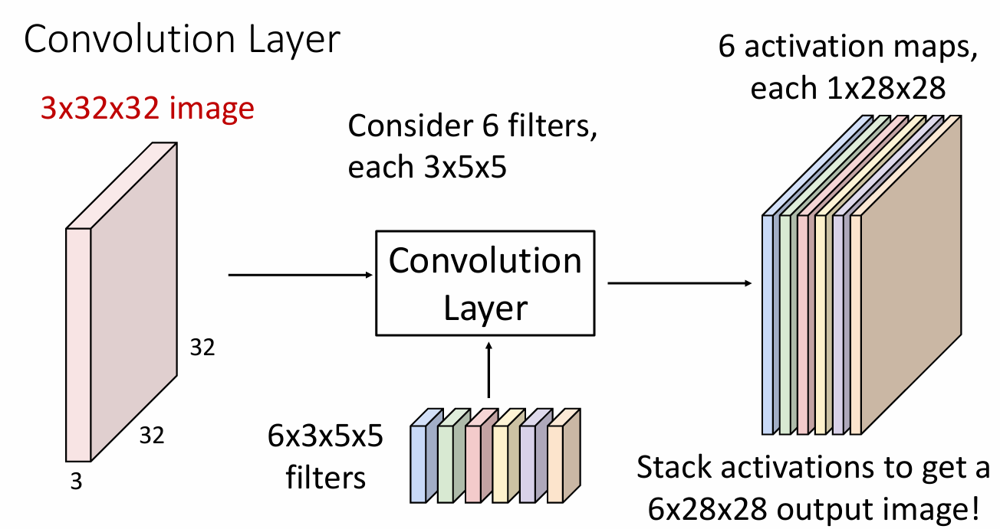
    (3x5x5 filter가 여섯 -> feature map 차원 : 6)

    **예시**
    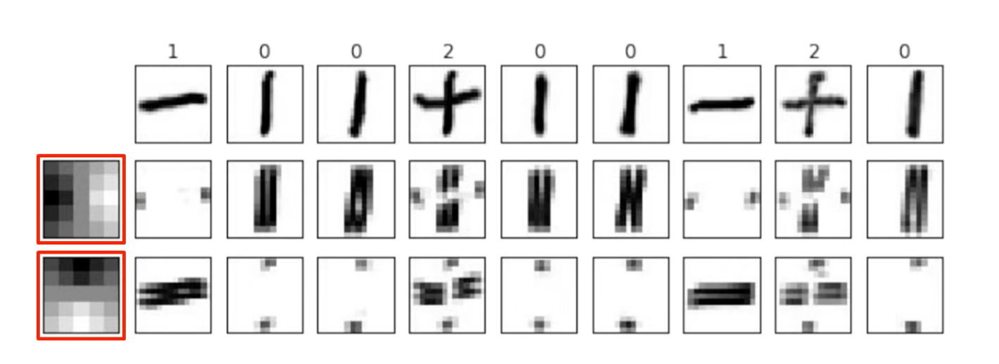
    - CNN은 여러 개의 필터를 사용하여 이미지의 다양한 특징 추출 가능
    - 예를 들어 세로 방향의 경계선을 감지하는 필터와 가로 방향의 경계선을 감지하는 필터를 각각 적용한다면, 세로선에 반응하는 필터는 이미지에서 세로 방향의 경계를 강조, 가로선에 반응하는 필터는 가로 방향의 경계를 강조함!
    - 이처럼 필터마다 서로 다른 특징을 추출하고, 여러 개의 Feature Map을 생성하여 이미지에 포함된 다양한 정보를 학습

2. **Padding**
- **개념**
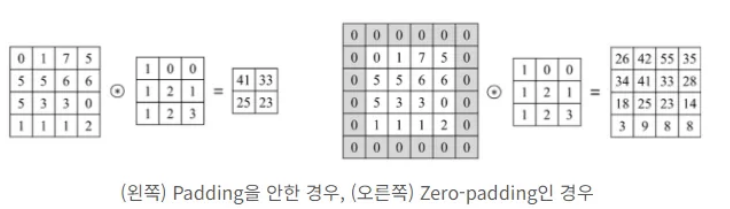

    Convolution 연산을 수행하기 전에 입력 이미지의 가장자리에 추가적인 픽셀을 삽입하는 방법

    일반적으로 이미지 바깥쪽에 0을 추가하는 Zero Padding 방식을 많이 사용

    필터는 입력 이미지의 범위 안에서만 이동할 수 있기 때문에 Padding을 적용하지 않으면 가장자리 영역은 필터가 적용되는 횟수가 상대적으로 적다. Padding은 이러한 문제를 보완하고 Feature Map의 크기를 조절하는 역할 수행!

- **효과**
    
    **예) 4 × 4 이미지에 3 × 3 필터를 적용하는 경우** Padding을 적용하지 않으면 4 × 4 입력 이미지에 3 × 3 필터를 적용했을 때 Feature Map의 크기는 3 × 3이 된다!

    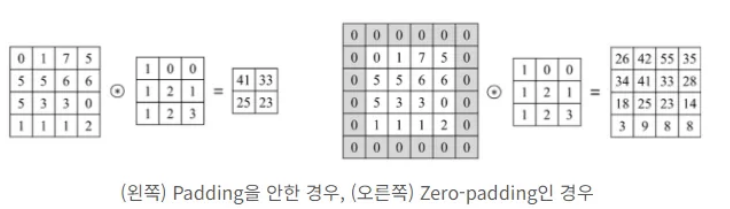

    - 반면 Padding을 1로 설정하면 이미지의 위, 아래, 왼쪽, 오른쪽에 각각 0을 한 줄씩 추가해요. 따라서 입력 이미지가 6 × 6로 확장되고, 연산 결과는 4 × 4가 됩니다.

    Padding을 적절하게 적용하면 Convolution 연산으로 인해 이미지의 크기가 지나치게 작아지는 것을 방지할 수 있고, 이미지 가장자리의 픽셀 또한 필터 연산에 충분히 포함되도록 합니다.

    따라서 Padding은 **이미지의 공간적 크기를 유지하면서 가장자리의 특징까지 학습할 수 있도록 하는 역할수행!**

3. **Stride (보폭)**
- **개념**
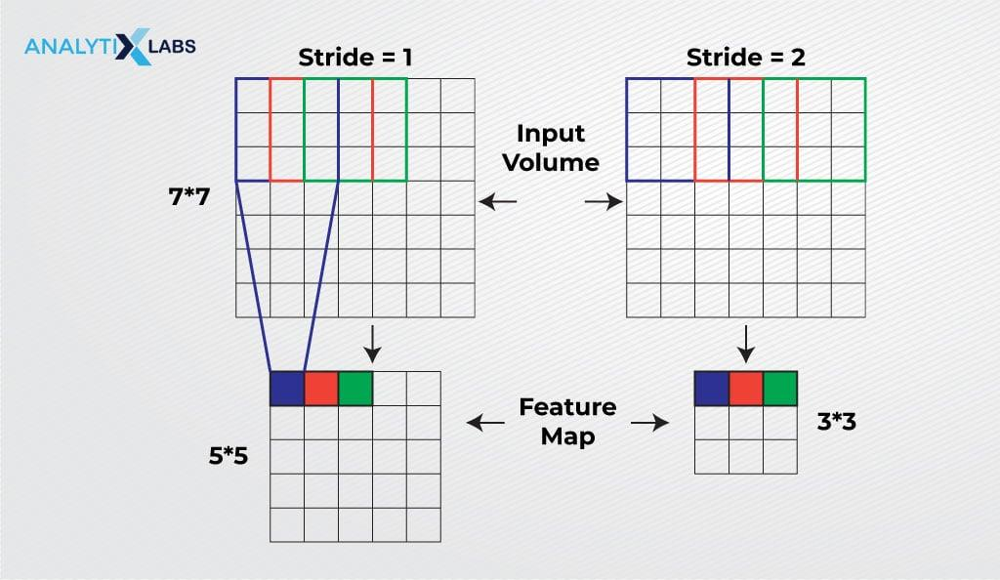

**Stride = 1**

- 한 칸씩 이동
- 이미지의 여러 위치를 세밀하게 확인
- Feature Map의 크기가 상대적으로 큼

**Stride = 2**

- 두 칸씩 이동
- 일부 위치를 건너뛰며 연산
- Feature Map의 크기가 상대적으로 작음

- **특징**
    - Stride가 커질수록 **필터가 한 번에 이동하는 거리가 늘어나므로 입력 이미지에서 연산하는 위치가 줄어듬!**

    - 그 결과 Feature Map의 가로와 세로 크기가 작아지고, 처리해야 할 데이터의 양도 감소

    - 따라서 Stride는 **특징을 얼마나 세밀하게 추출할지와 연산 효율을 어떻게 조절할지 결정하는 요소**입니다.

    - Stride가 1이면 필터가 더 많은 위치를 확인하기 때문에 **세부적인 특징을 추출하는 데 유리**

    - 반면, Stride가 2 이상이면 필터가 이동하는 횟수가 줄어들기 때문에 **연산량을 줄이고 Feature Map의 크기를 축소 가능**

4. **Pooling**

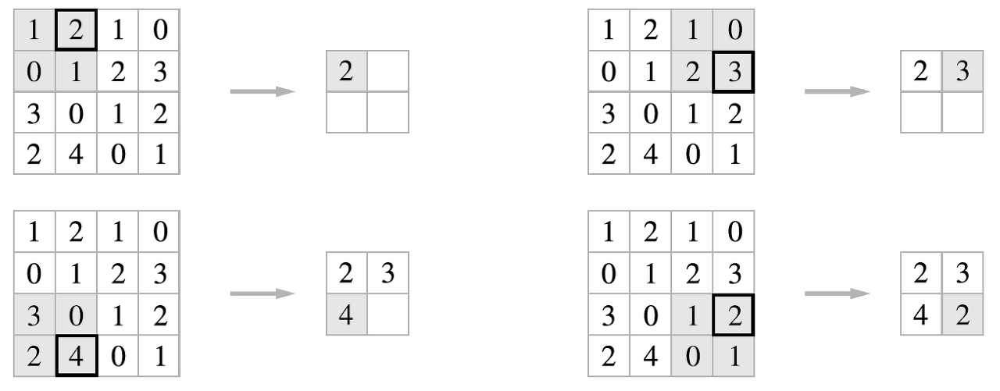

- **개념**
    - Pooling은 이미지의 작은 위치 변화에 대한 민감도를 낮춰 모델이 특징을 더 안정적으로 인식할 수 있도록 도와줌.
    
    - 일정한 크기의 영역을 설정하고, 해당 영역에 포함된 값들을 하나의 값으로 요약
    - 일반적으로 2 × 2 크기의 영역을 사용하며, 각 영역에서 최댓값이나 평균값을 계산하는 방식 존재
    - Pooling을 통해 이미지의 공간적 크기를 축소하고, 이후 단계에서 처리해야 하는 데이터의 양을 줄일 수 있음

- **Pooling의 종류**

    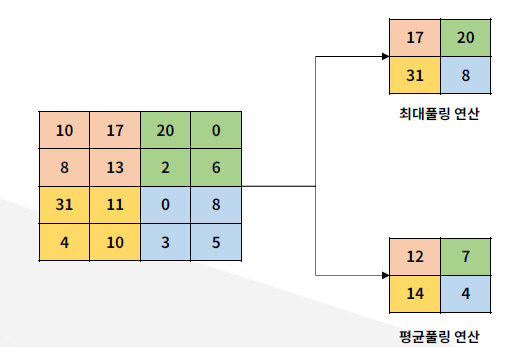

    - **Max Pooling** : 지정된 영역 안에서 가장 큰 값을 선택하는 방식
    - **Average Pooling** : 지정된 영역 안에 있는 모든 값으 평균을 계산하는 방식

- **장단점**
    - **장점**
        - **차원 축소로 계산량 감소** : Feature Map의 가로와 세로 크기를 줄여 이후 계층의 연산 부담을 낮춘다!
        - **위치 변화에 대한 강건성** : 주변 영역의 값을 요약하기 때문에 작은 위치 변화에도 비슷한 특징을 유지할 수 있다!
        - **과적합 방지에 도움** : 불필요한 세부 정보와 공간적 복잡성을 줄여 모델이 특정 위치에 지나치게 의존하는 현상을 완화하는 데 도움을 줄 수 있다!
        - **노이즈 영향 완화** : 작은 값들이 주변의 강한 특징에 비해 상대적으로 덜 반영될 수 있다! 단, 모든 종류의 노이즈를 제거하는 것은 아님
    - **단점**
        - **정보 소실의 위험** : Feature Map의 크기를 줄이는 과정에서 일부 세부 정보가 사라질 수 있다!
        - **정확한 위치 정보 감소** : 객체의 경계나 세밀한 위치 정보가 중요한 작업에서는 Pooling으로 인한 정보 손실이 문제가 될 수 있다!

#### **CNN 구조 정리**

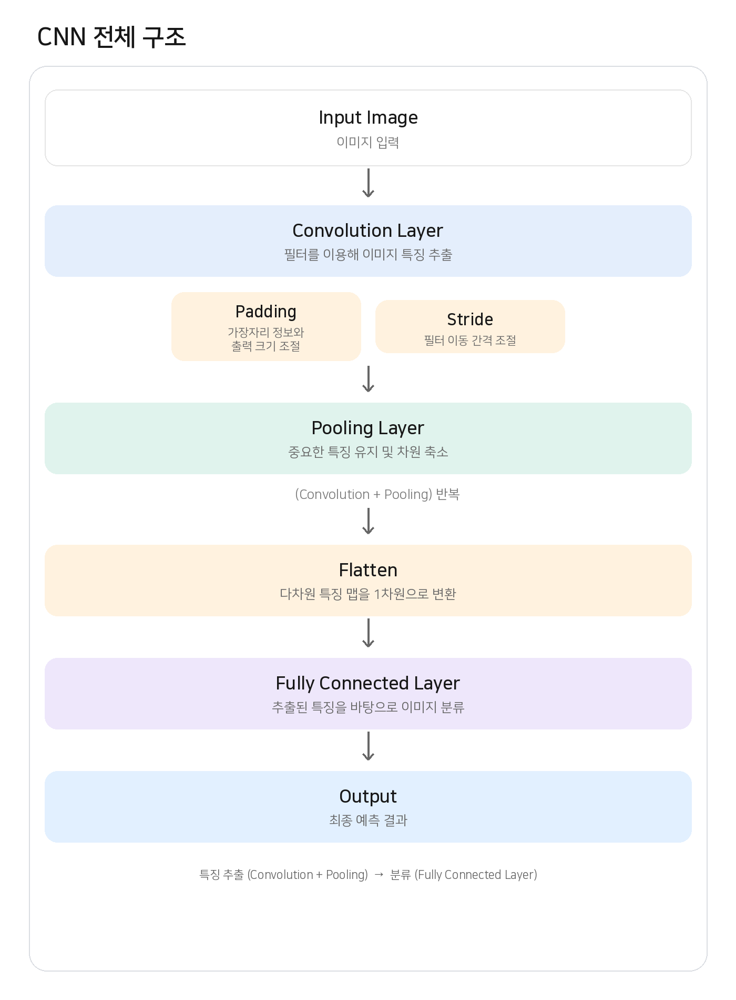

### **4. 대표적인 CNN 아키텍처**
#### **1. AlexNet (2012)**

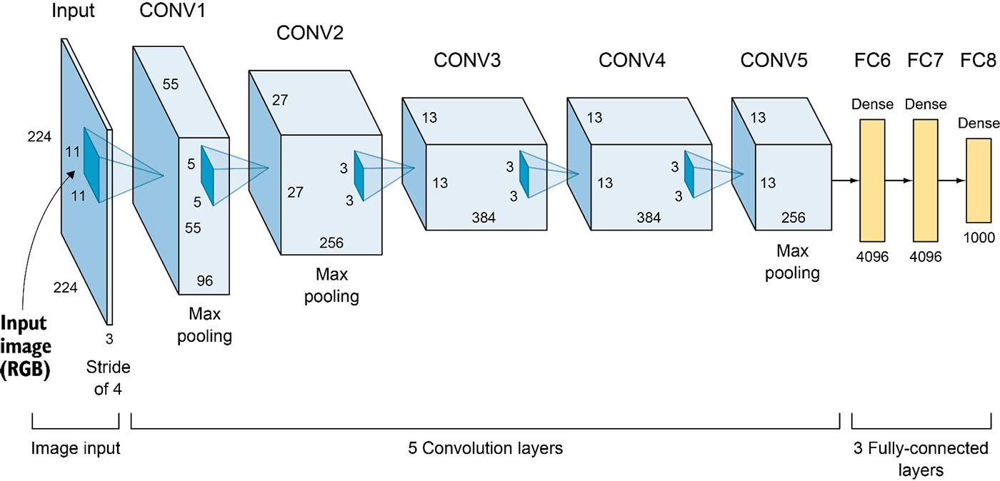

- **개념**
    - 2012년 ImageNet 이미지 분류 대회(ILSVRC)에서 뛰어난 성과를 거둔 CNN 모델
    - 대규모 이미지 데이터를 활용해 이미지의 특징을 직접 학습하고 분류하는 딥러닝의 가능성을 보여준 대표적인 모델
- **구조**
    - 총 8개의 학습 계층으로 구성
        - Convolution Layer 5개
        - Fully Connected Layer 3개
    - Convolution Layer에서 이미지의 특징을 추출하고, 마지막 Fully Connected Layer에서 이미지의 클래스를 분류
    - 중간에 ReLU 활성화 함수와 Max Pooling을 적용
- **주요 특징**
    
    **딥러닝 역사에 기여한 5가지 혁신 기술**
    
    - **ReLU 활성화 함수 도입:** 기존에 사용되던 Tanh 함수 대신 **ReLU(Rectified Linear Unit)** 를 사용하여 기울기 소실(Gradient Vanishing) 문제를 해결하고 학습 속도를 6배 이상 향상
    - **다중 GPU 병렬 연산:** 당시 부족했던 3GB 용량의 GPU(Nvidia GTX 580) 2개를 병렬로 연결하여 네트워크 구조를 상-하단으로 분할해 학습
    - **드롭아웃(Dropout):** 과적합(Overfitting)을 막기 위해 훈련 과정에서 완전연결 계층의 뉴런 중 일부(예: 50%)를 무작위로 끄고 학습
    - **데이터 증강(Data Augmentation):** 이미지를 무작위로 잘라내거나(Crop) 좌우 반전, RGB 채널 값 변경(PCA 이용)을 통해 인위적으로 훈련 데이터를 대폭 증가
    - **로컬 응답 정규화(LRN):** 측면 억제(Lateral Inhibition) 개념을 모델에 적용해 강하게 활성화된 뉴런 주변을 감쇠 (최근에는 주로 배치 정규화(Batch Normalization)로 대체)


#### **2. VGGNet (2014)**

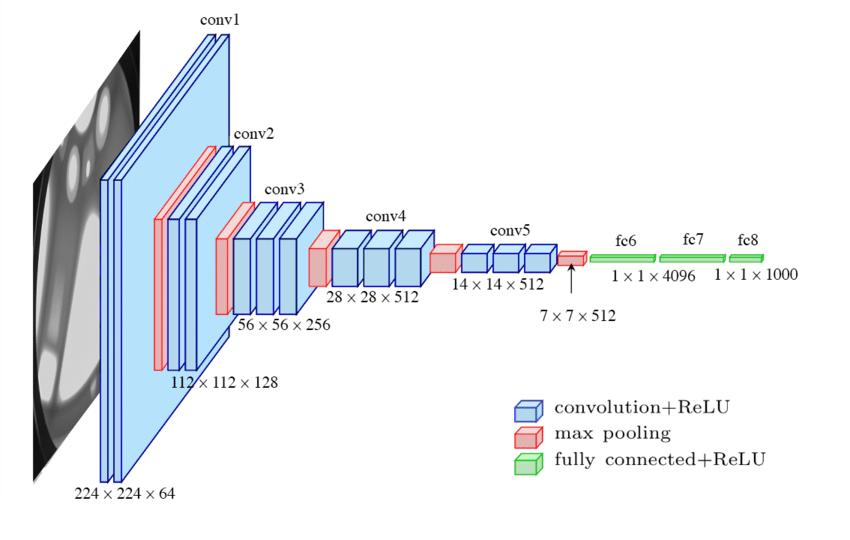

- **개념**
    - VGGNet은 옥스퍼드대학교 연구팀이 개발한 CNN 모델로, 네트워크의 깊이를 늘리면 이미지 인식 성능이 향상될 수 있다는 점을 보여준 모델
    - 대표적으로 VGG16과 VGG19 존재. 숫자는 학습 가능한 계층의 수를 의미
- **구조**
    - 대표 모델인 VGG16은 총 16개의 학습 계층으로 구성
        - Convolution Layer 13개
        - Fully Connected Layer 3개
    - 작은 크기의 3 × 3 필터를 반복적으로 적용하고, 중간중간 Max Pooling을 사용
    - 여러 Convolution Layer를 쌓아 이미지의 특징을 단계적으로 추출
- **주요 특징**
    - 작은 필터의 반복 사용: 3 × 3 크기의 작은 필터를 여러 번 적용해 다양한 특징을 학습
    - 깊은 네트워크: AlexNet보다 더 많은 계층을 쌓아 복잡하고 추상적인 이미지 특징을 학습
    - 일관된 구조: 대부분의 Convolution Layer에서 동일한 3 × 3 필터를 사용하여 구조가 비교적 단순하고 이해하기 쉬움

**AlexNet에서 발전한 점**

- AlexNet은 비교적 큰 필터와 적은 수의 Convolution Layer를 사용하는 점에 비해 VGGNet은 3 × 3 크기의 작은 필터를 반복적으로 적용하고 네트워크를 더 깊게 구성
- 이를 통해 이미지의 단순한 특징부터 복잡한 형태까지 더욱 세밀하게 학습할 수 있도록 발전


#### **3. ResNet (2015)**

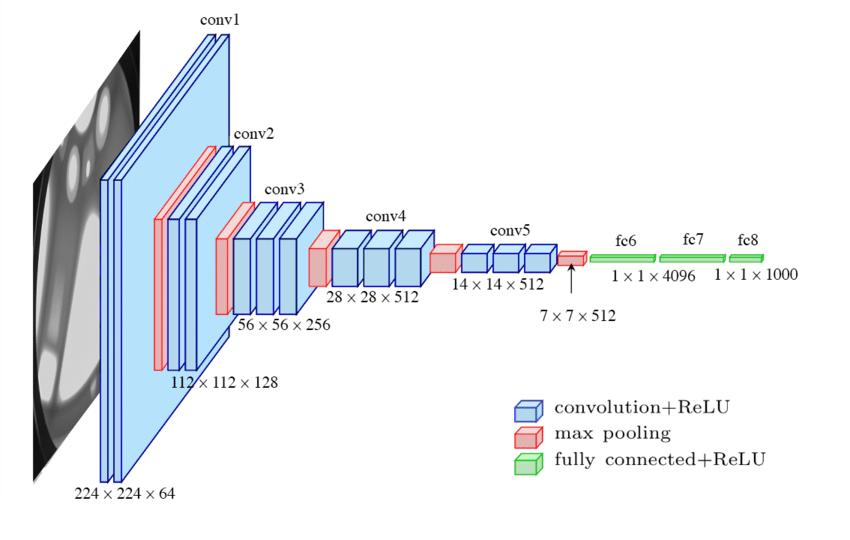

- **개념**
    - ResNet(Residual Network)은 깊은 신경망을 효과적으로 학습하기 위해 개발된 CNN 모델
    - 기존 신경망의 단순한 계층 연결 방식에서 벗어나 잔차 연결(Residual Connection) 이라는 구조를 도입
- **구조**
    
    **핵심 혁신 기술: 잔차 학습(Residual Learning)과 지름길(Shortcut)**
    
    - 여러 개의 Convolution Layer 사이에 Skip Connection을 추가한 구조
    - Skip Connection은 입력 정보를 중간 계층을 거치지 않고 뒤쪽 계층으로 직접 전달하는 연결 방식
    - 기존의 계층을 통과한 결과와 처음 입력된 정보를 더해 다음 계층으로 전달

## **2. 이미지 딥러닝 응용**
### **1. 이미지 분류 (Image Classification)**
- **이미지 분류 모델**
    - 이미지를 수치 데이터(픽셀 값)로 인식 -> 사전 정의된 클래스 중 하나로 분류

| 모델명 | 특징 요약 | 주의사항 |
| --- | --- | --- |
| **AlexNet** | 비교적 단순한 구조, 초기 CNN 모델들 | 작은 데이터셋이나 학습 개념 설명용으로 적절 |
| **VGG** | 더 깊은 구조, 복잡한 블록 구조 적용 | 계산량 증대, 메모리 요구 높음 |
| **ResNet** | Residual 연결 (skip connections) → 매우 깊은 네트워크 가능 | 과적합 주의, batch size / regularization 조절 필요 |
| **Vision Transformer (ViT)** | Transformer 구조 응용 → 패치 기반 입력 처리 | 이미지와 순차 처리 모델의 결합, 대규모 데이터 필요 |
- **ViT(Vision Transformer)**
    
    이미지를 작은 패치(Patch) 단위로 나누고, 이를 Transformer에 입력하여 이미지의 특징을 학습하는 모델. CNN처럼 필터를 반복적으로 적용하는 대신 Attention을 활용해 이미지 패치 간의 관계를 학습함.
    

- **CNN의 확장 가능성**
    - **YOLO (You Only Look Once)**

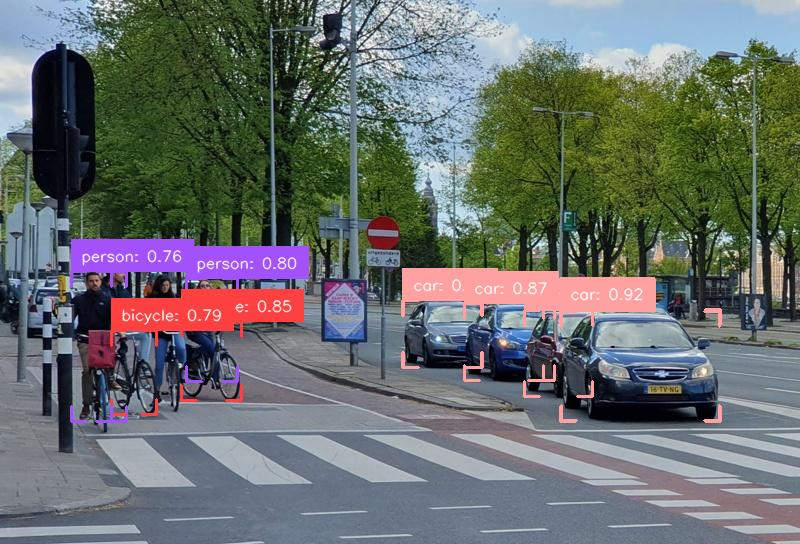

- CNN은 이미지 전체를 하나의 클래스로 분류하는 작업뿐 아니라, **이미지 안에 존재하는 여러 객체를 찾아내는 작업에도 활용됨**
- 대표적인 모델인 **YOLO**는 이미지 안의 사람, 자동차, 자전거 등을 각각 탐지하고, 객체의 종류와 위치를 동시에 예측! 이처럼 CNN은 이미지 분류 외에도 객체 탐지와 같은 다양한 작업에 활용될 수 있다!

### **2. 객체 탐지 (Object Detection)**
**객체 탐지**는 이미지 분류에서 한 단계 확장된 작업. 이미지 분류가 이미지 전체에 어떤 클래스가 있는지 예측한다면, 객체 탐지는 **이미지 안에 있는 개별 객체의 종류와 위치를 함께 예측한다!**

- **Bounding Box**

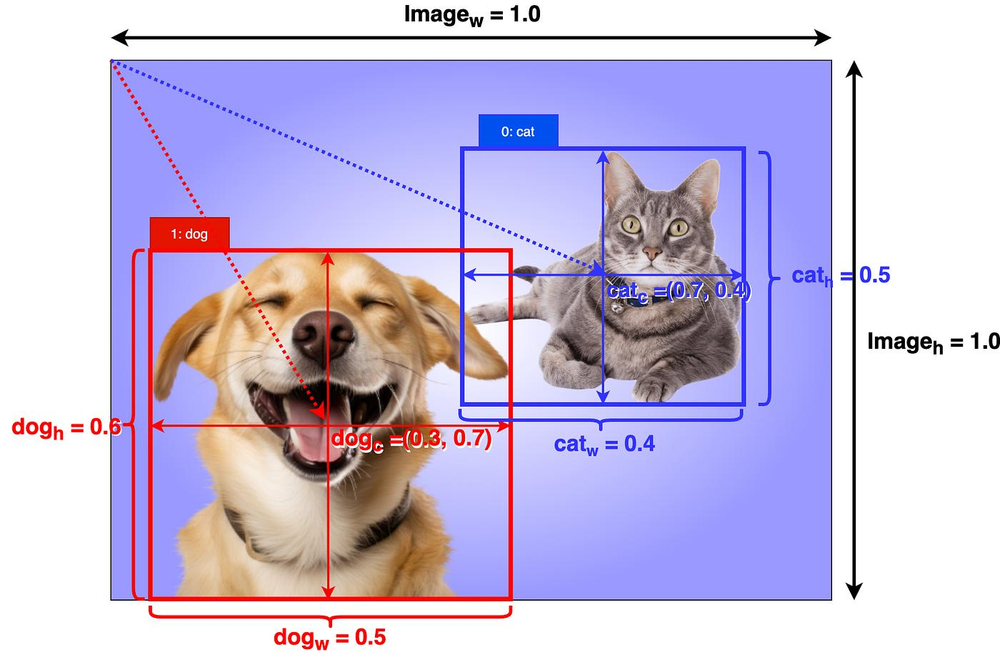

- Bounding Box는 이미지에서 객체가 위치한 영역을 둘러싸는 사각형
- 객체 탐지 모델은 사각형의 위치와 크기를 예측하여 이미지 안에서 객체가 어디에 있는지 표시함
- 일반적으로 중심 좌표 (x,y), 너비 (w), 높이 (h)를 이용하여 위치를 표현

- **모델 적용 방식**
    
    CNN으로 Feature Map을 얻고 그 위에 두 개의 head를 올리는 구조
    
    - **Classification Head : 객체의 종류 예측**
        - 이미지에서 탐지한 객체가 어떤 종류에 속하는지 예측
        - 예를 들어 해당 객체가 사람인지, 자동차인지, 강아지인지 판단
    - **Regression Head : 객체의 위치 좌표 예측**
        - 객체를 둘러싸는 Bounding Box의 위치와 크기를 예측
        - 중심 좌표와 너비, 높이 등의 값을 계산하여 객체가 이미지의 어느 위치에 있는지 표시
    - 대표 모델 : YOLO, Faster R-CNN, SSD

### **3. 이미지 캡셔닝 (Image Captioning)** 
**이미지 캡셔닝**은 **이미지의 내용을 자연어 문장으로 표현하는 작업!** 이 과정에서 이미지 특징을 추출하는 **CNN**과 문장을 생성하는 **RNN**이 함께 사용됨.

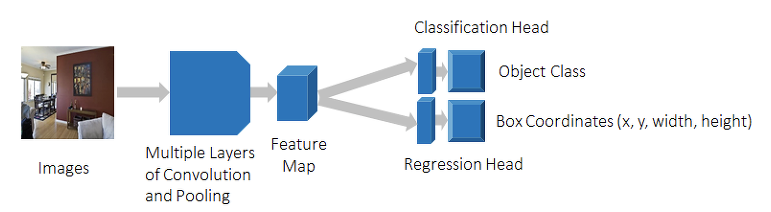

- 객체에 대한 판단을 넘어 객체들 간의 관계를 파악하고 자연어 형태로 표현하는 작업
- 예를 들어 이미지 속에서 사람, 자전거, 도로라는 객체를 각각 찾아내는 것에서 끝나는 것이 아닌, 사람이 자전거를 타고 있다는 객체 간의 관계와 행동까지 파악하여 문장으로 표현

- **이미지 캡셔닝 결과 예시**

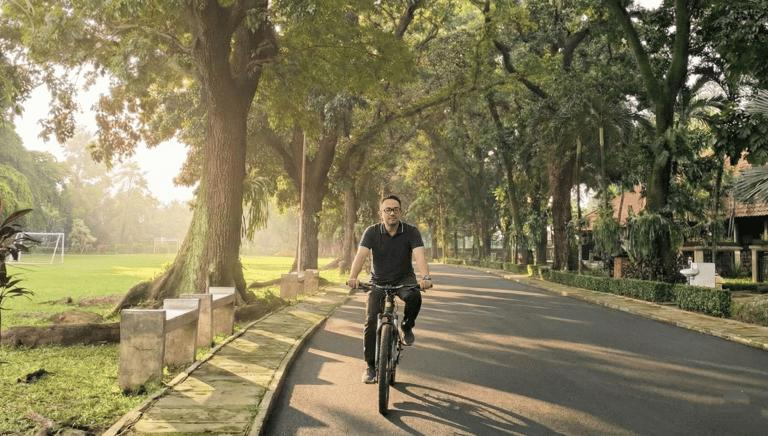

**→ “한 사람이 도로에서 자전거를 타고 있습니다.”**

- **모델 적용 방식 : CNN과 RNN**
    - **CNN : 이미지 특징 추출**
        - 이미지에서 사람, 자전거, 도로와 같은 객체 및 시각적 특징을 추출
    - **RNN : 문장 생성**
        - CNN이 추출한 이미지 특징을 바탕으로 단어를 순서대로 생성
        - 이전에 생성한 단어 정보를 활용하여 다음에 올 단어를 예측하고 하나의 문장을 완성

- **이미지 캡셔닝 단계**
    
    **1️. CNN을 이용한 특징 추출**
    
    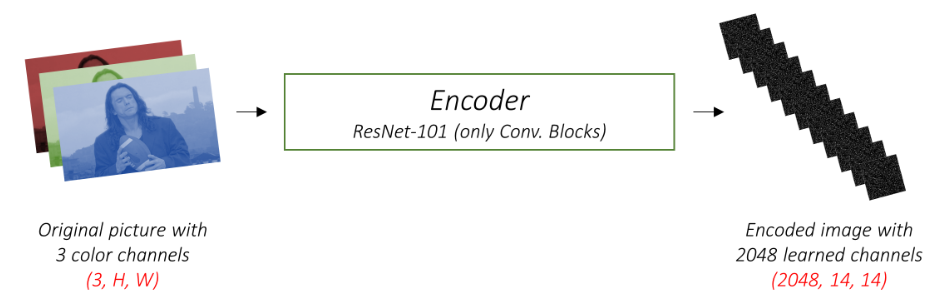
    
    **2️. Attention Network를 이용하여 단어 생성**
    
    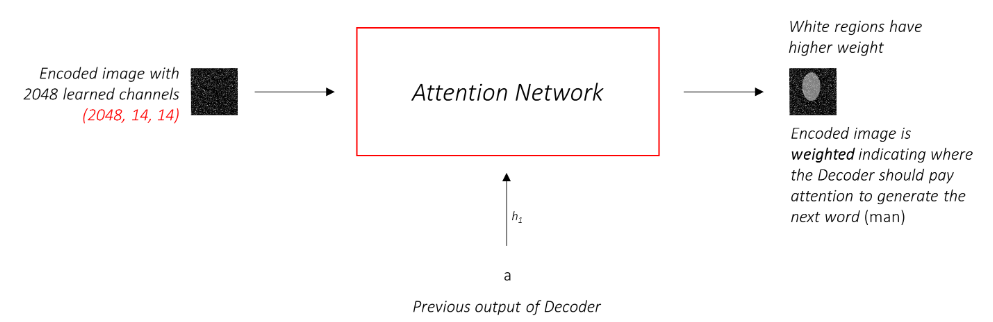
    
    - **Attention**은 문장을 생성할 때 이미지의 모든 영역을 동일하게 고려하지 않고, 현재 생성하려는 단어와 관련된 중요한 영역에 더 높은 가중치를 부여하는 방식
    - 예를 들어 '사람'이라는 단어를 생성할 때는 사람의 영역에, '자전거'라는 단어를 생성할 때는 자전거의 영역에 더 집중할 수 있음
    
    즉, 문장을 생성하는 데 중요한 이미지 영역에 더 높은 가중치를 둔다는 개념!
    
    - RNN을 이용하여 문장 완성
        
        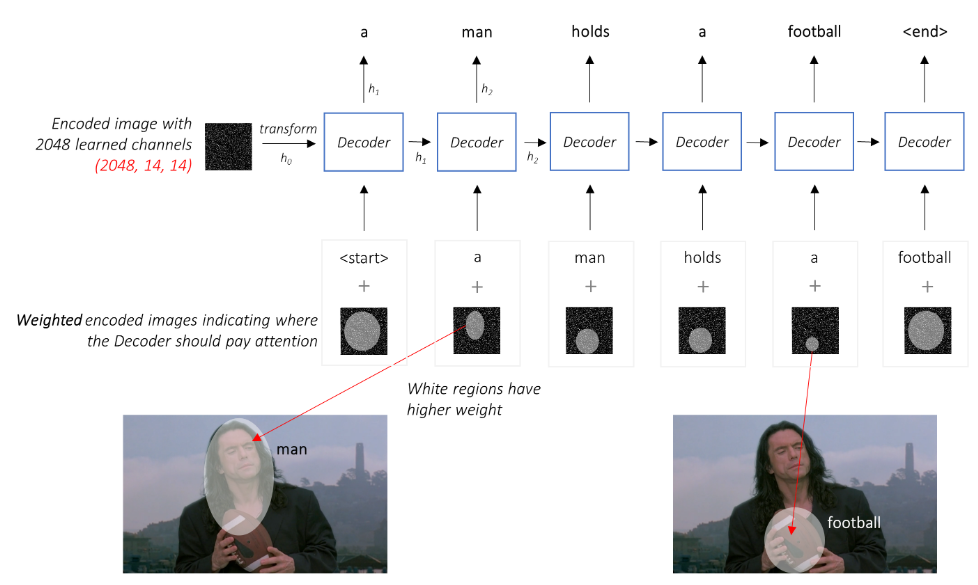
        
- **CNN 세 줄 요약**
    
    1. (Conv + Pool)의 반복으로 특징을 학습한다!
    
    2. FC Layer를 적용하여 이미지를 분류한다!
    
    3. (Conv + Pool)에 어떤 방법을 적용하느냐에 따라 성능이 달라진다!   

### **3. 과거를 기억하는 신경망 : RNN (Recurrent Neural Network)**
#### **3-1. 순차(Sequence) 데이터**
1. **순차 데이터란?** : 데이터의 순서가 의미를 갖는 데이터로, 순서를 바꾸면 정보가 달라지는 데이터

2. **순차 데이터 세부 분류**
1) 순서의 기준

| 구분 | 시간적 순차 데이터 | 비시간적 순차 데이터 |
| --- | --- | --- |
| 기준 | 시간 순 | 시간 외 기준 (위치, 순번) |
| 예시 | 주가, 기온 | 문장 내 단어, DNA 염기서열 |
2) 자료형

| 구분 | 수치형 | 범주형 |
| --- | --- | --- |
| 특징 | 값의 크기와 거리에 의미 O | 값의 크기와 거리에 의미 X |
| 예시 | 음성, 비디오 | 웹 클릭 로그, 구매 이력 |
- 음성, 비디오가 어떻게 수치형 순차 데이터일까?
    
    **음성 (Audio)**
    
    - 소리 = 시간에 따라 계속 변하는 공기의 진동
    - 컴퓨터는 소리를 아주 짧은 간격으로 잘라 진폭 값을 기록
        - 예) 16kHz = 1초에 16,000번 진폭 값 기록
    - 각 시점에서 측정된 진폭값을 정수나 실수 형태의 수치로 변화
    - 시간 순서를 변화시키면 전혀 다른 데이터가 됨
    
    **비디오 (Video)**
    
    - 영상 = 이미지(프레임)을 빠르게 연속으로 넘긴 것
        - ex) 30프레임 → 1초에 30장을 빠르게 넘긴 것
    - 이미지는 픽셀들로 구성되고 각 픽셀값은 **수치**
    - 프레임 재생 순서가 뒤섞이면 의미가 완전히 달라짐
    - 시점 t의 프레임은 이전 시점 t-1의 객체 위치와 움직임에 직접적인 영향을 받음

- **예시**
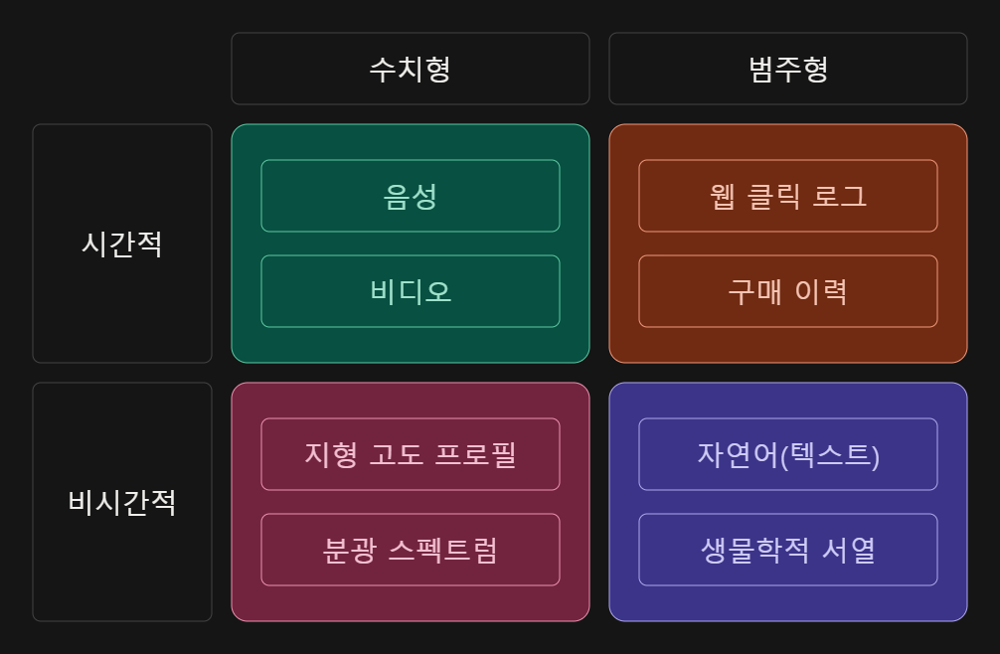

3. **기존 정형 데이터 vs. 순차 데이터**

| 비교 관점 | 정형 데이터 | 순차 데이터 |
| --- | --- | --- |
| 순서를 섞으면? | 의미 그대로 ✅ | 의미가 달라짐 ❌ → **요소의 순서의존성** |
| 샘플 간 관계 | 상호독립적 | 상호의존적
 → 이전 시점/순번이 현재 시점/순번에 영향
→ **자기상관성** |
| 예시 | 고객 정보 데이터 | 주가, 문장 |

- **정형 데이터** : 고객 A, B, C 행 순서를 C, A, B로 바꿔도 → **의미 변화 X**
- **순차 데이터** : "개가 사람을 물었다" → "사람이 개를 물었다" → **완전히 다른 의미**

- 기존 머신러닝 기법(회귀, 결정트리, SVM)은 정형 데이터를 전제로 설계되어서 순차 데이터를 처리하는 데 한계 존재 -> 순차 데이터를 처리할 별도 모델 필요!! -> **RNN**

#### **2. RNN(Recurrent Neural Network, 순환신경망)의 구조와 원리**
#### **1. 구조**
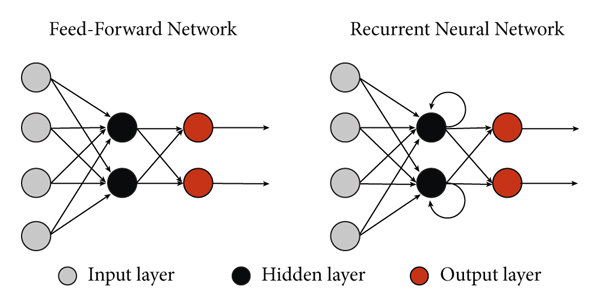
-> 기존신경망과 비교했을 떄 가장 큰 차이점 : 은닉층에 **순환 구조** 존재!

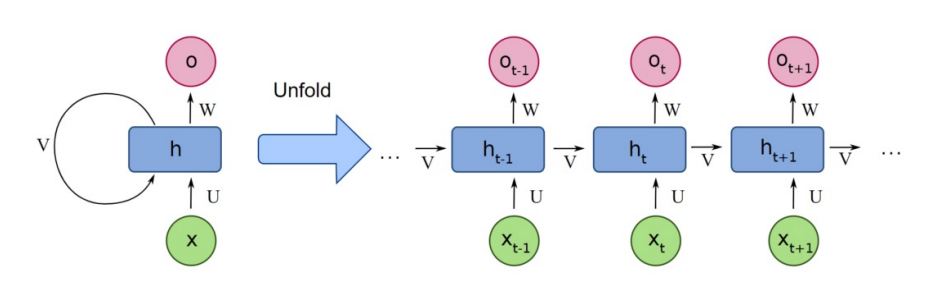

- **입력층** ($x$) : 각 시점 t에 들어오는 입력 데이터  xₜ를 받는 곳
- **은닉층** ($h$): 현재 입력 xₜ와 이전 시점의 은닉 상태 hₜ₋₁를 함께 받아 새로운 은닉 상태 hₜ를 만드는 곳
- **출력층** ($o$): 은닉 상태 hₜ를 바탕으로 시점 t의 결과 oₜ를 내보내는 곳
- **입력 가중치** ($U$): 입력 데이터 xₜ를 은닉층으로 보낼 때 붙는 가중치
- **순환 가중치** ($V$) : 이전 은닉 상태 hₜ₋₁를 현재 은닉층으로 보낼 때 붙는 가중치
- **출력 가중치** ($W$): 은닉 상태 hₜ를 출력 oₜ로 바꿀 때 붙는  가중치

#### **2. 원리**
- **핵심**  : 매 시점마다 현재 시점 입력값과 이전 시점 은닉상태를 이용해 현재의 은닉상태를 계산하고 그 결과를 다음 시점으로 넘겨줌
- **은닉 상태(**$hₜ$) **계산** : 현재 입력 $xₜ$ + 이전 은닉 상태 $hₜ₋₁$ → 새로운 은닉 상태 $hₜ$
    
    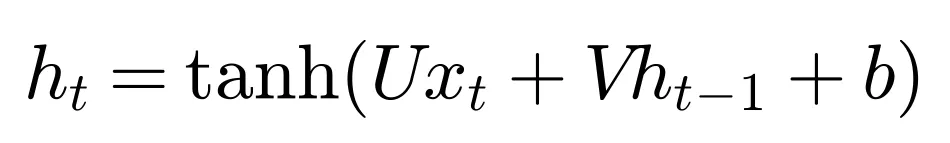
    
    - tanh - 하이퍼볼릭탄젠트 함수
        
        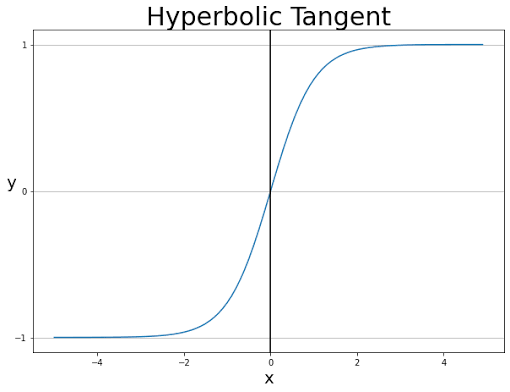
        
        $$
        \tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}} = \frac{\sinh(x)}{\cosh(x)}
        $$
        
        - 값을 -1 ~ 1 사이로 값을 제한해서 은닉 상태값이 폭주하는 것을 막아줌
        - 비선형성 추가 →  복잡한 패턴을 학습할 수 있게끔
    - $b$: 편향
- **출력 계산** : 은닉 상태 $hₜ$로 현재 시점의 출력을 만듦
    
    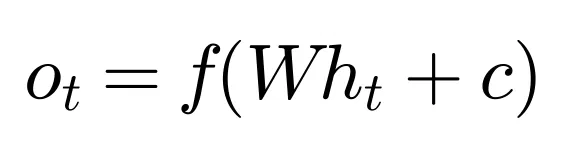
    
    - $f(활성화함수)$
        - 이진 분류 문제라면 시그모이드 함수
            
            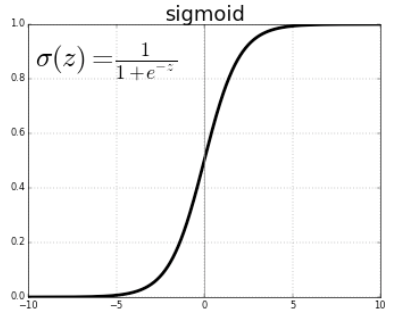
            
            - 값을 0과 1사이의 값으로 압축
            - 출력값이 특정값 이상이면 1(True), 특정값 이하면 0(False)로 정해서 이진 분류 문제를 풀 때 활용
        - 다중 분류 문제라면 소프트맥스 함수

            $$
            \text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}
            $$
            
            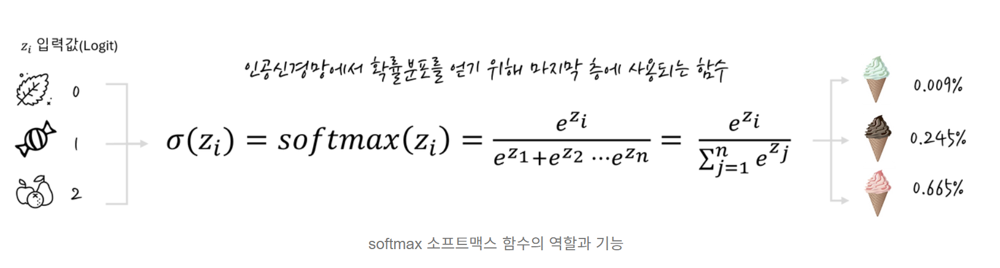
            
            - 입력받은 각 점수를 지수함수로 변환한뒤 전체 클래스의 지수 합으로 나누어줌
            - 출력값은 0에서 1사이 값
            - 전체 출력값의 합은 항상 1
    - $c$: 편향

- **예시** : "나는 / 밥을 / 먹었다"
    
    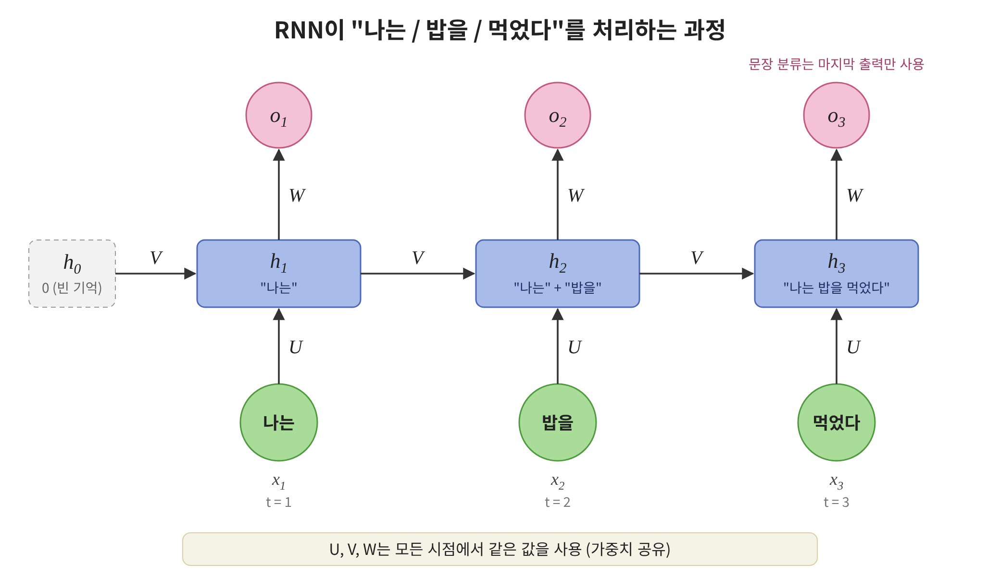
    
    - t=1 : "나는" 입력값 처리, 은닉상태로 다음상태 은닉층에 값 전달
    - t=2 : "나는" + "밥을" 정보 저장
    - t=3 : 문장 전체 맥락이 h₃에 요약되고 활성화함수 거쳐서 최종 출력

#### **3. RNN 아키텍처**
- **One to Many - 하나의 입력에서 시퀀스(순서가 있는 데이터의 나열) 출력**
    
    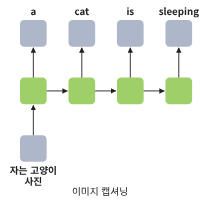
    
    - 이미지 캡셔닝에 사용 
    → 사진 첫 시점에 한 번만 넣으면 은닉 상태 거치면서 사진의 제목 출력하는 기능

- **Many to One - 시퀀스 입력에서 하나의 값 출력**
    
    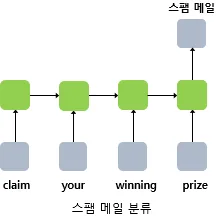
    
    - 스펨 메일 분류
        - 문장을 순차적으로 읽은 후 스펨메일인지 아닌지를 판별
    - 감성 분류
        - 문장을 순차적으로 읽은 후 감성을 판별
        - 이진 감성 분류 - 긍정/부정
        - 다중 감성 분류 - 기쁨/분노/슬픔/놀람
    - 전체 문장을 읽은 후 최종 판별을 하므로 many to one 구조 사용

- **Many to Many - 시퀀스 입력에서 시퀀스 출력**
    
    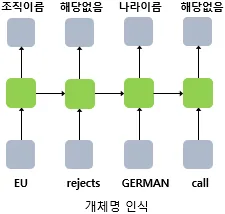
    
    - 동기식 Many to Many - 매 시점마다 즉각 출력
        - 객체 태깅 등에 활용
    - 비동기식 Many to Many - 전체 입력을 끝가지 읽은 뒤 한 번에 출력
        - 기계 번역, 요약 등에 활용

### **3-3. RNN의 한계 및 장기 의존성 문제**
#### **1. RNN 한계점**
1. **시간에 따른 역전파(Back Propagation Through Time) 구조**

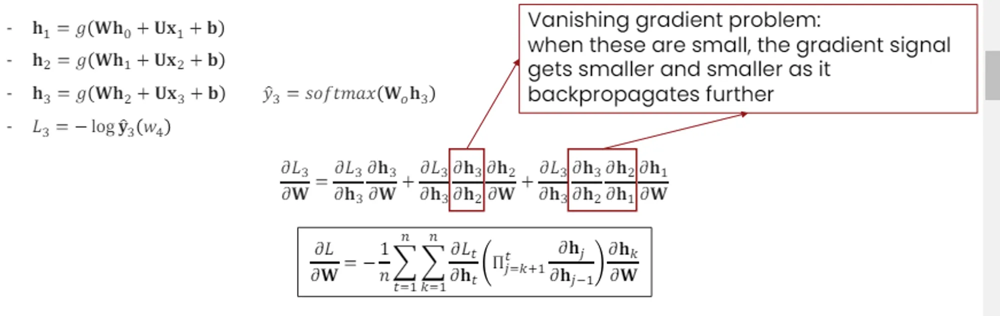

- RNN은 순전파를 통해 시퀀스를 처리한 뒤, **시간을 거슬러 올라가며(BPTT) 오차를 전파하여 가중치 기울기를 누적 계산**함
    - 가중치 기울기(Gradient) 계산
        - 가중치를 살짝 늘렸을 때 오차가 얼마나 변하는가'를 측정하여, 오차를 줄이기 위해 가중치를 어느 방향으로 얼만큼 이동시킬지 결정하는 과정
        
    - chain rule에 의해 한 시점을 거슬러 갈 때마다  $∂hₜ/∂hₜ₋₁$ = (활성화 함수 미분값) × (순환 가중치)가 곱해짐

        **[RNN에서의 Chain Rule]**
        
        RNN은 h₁ → h₂ → h₃ → 출력층 → 오차 L 순서로 이어졌다고 했을 때
        
         h₁의 변화가 최종 오차(L)에 미치는 영향(기울기)을 구하려면, 중간 단계를 모두 곱해야 함
        
        **→ ∂L/∂h₁ = ∂L/∂h₃ × ∂h₃/∂h₂ × ∂h₂/∂h₁**
        
        $$
        \frac{\partial h_t}{\partial h_{t-1}} = \underbrace{\text{diag}\left(g'(a_t)\right)}_{\text{활성화 함수 미분값}} \ \times\underbrace{V}_{\text{순환 가중치}}
        $$
        
    - 같은 순환 가중치(V)를 모든 시점이 공유 → 같은 값이 계속 곱해지는 등비수열 형태
        - k시점 전까지 거슬러 가면 이 값이 k번 곱해짐 (Vᵏ 꼴)

2. **기울기 소실 (Vanishing Gradients)**
- 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 작아져 0에 가까워지는 현상
- 발생 원인
    
    $$
    \frac{\partial h_t}{\partial h_{t-1}} = \underbrace{\text{diag}\left(g'(a_t)\right)}_{\text{활성화 함수 미분값}} \ \times\underbrace{V}_{\text{순환 가중치}} < 1
    $$
    
    - tanh 미분값은 최대 1, 대부분 1보다 작음
    - V의 크기가 1보다 작으면 반드시 소실, 조금 커도 소실될 수 있음
- 특징
    - 기본 RNN에서 기울기 폭주보다 훨씬 자주 발생 (tanh미분값 ≤ 1 이기 때문에)
- 예시
    
    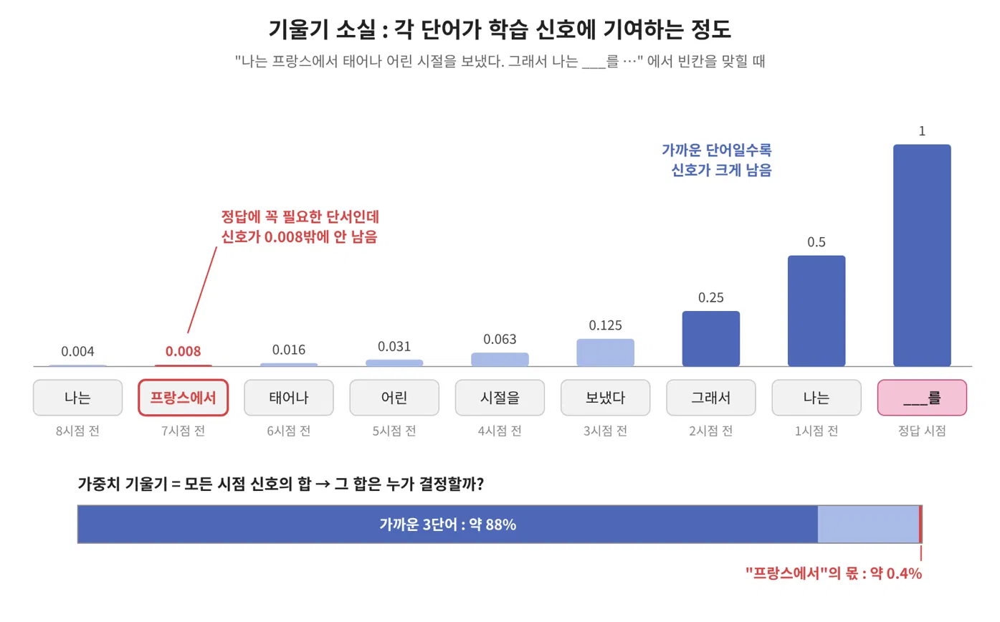    

**가까운 시점은 학습되지만, 먼 과거 시점의 정보는 학습에 거의 반영되지 않게됨**

3. **기울기 폭주 (Exploding Gradients)**
- 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 커져 매우 큰 값이 되는 현상
- 발생 원인
    
    $$
    \frac{\partial h_t}{\partial h_{t-1}} = \underbrace{\text{diag}\left(g'(a_t)\right)}_{\text{활성화 함수 미분값}} \ \times\underbrace{V}_{\text{순환 가중치}} > 1
    $$
    
- 특징
    - 가중치가 크게 튀면서 오차가 갑자기 치솟거나 진동함
        
        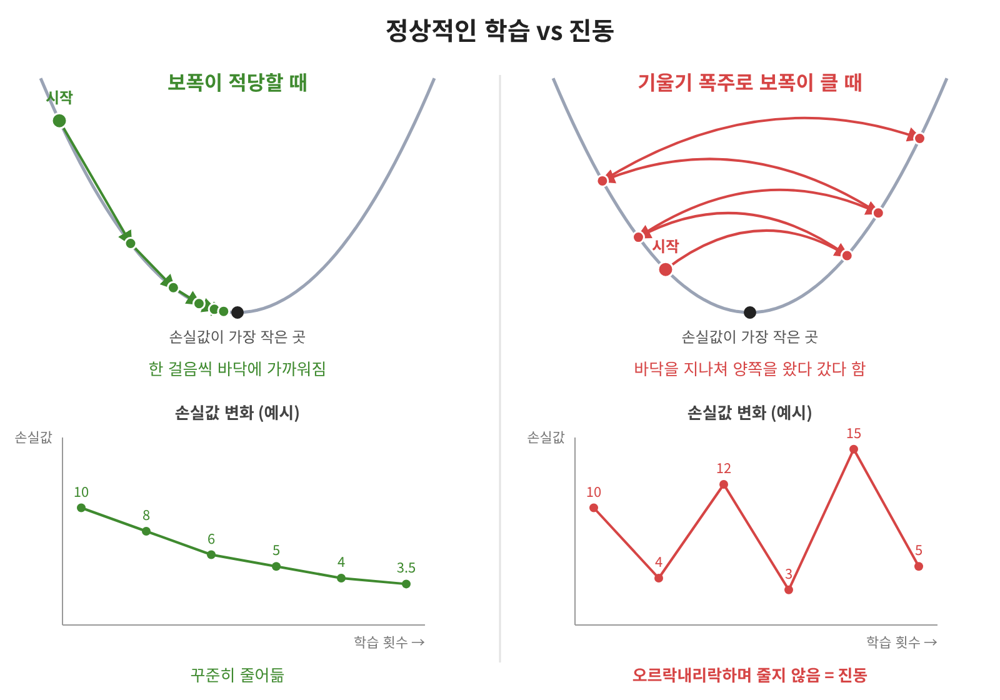
        
        **정상적인 학습 vs 진동**
        
        - **정상**: 10 → 8 → 6 → 5 → 4 → 3.5 … (점점 줄어듦)
        - **진동**: 10 → 4 → 12 → 3 → 15 → 5 … (오르락내리락하며 안 줄어듦)
        
    - 심하면 오차값이 너무 커져 NaN(계산 불가)이 발생하고 학습이 중단됨
- 예시
    
    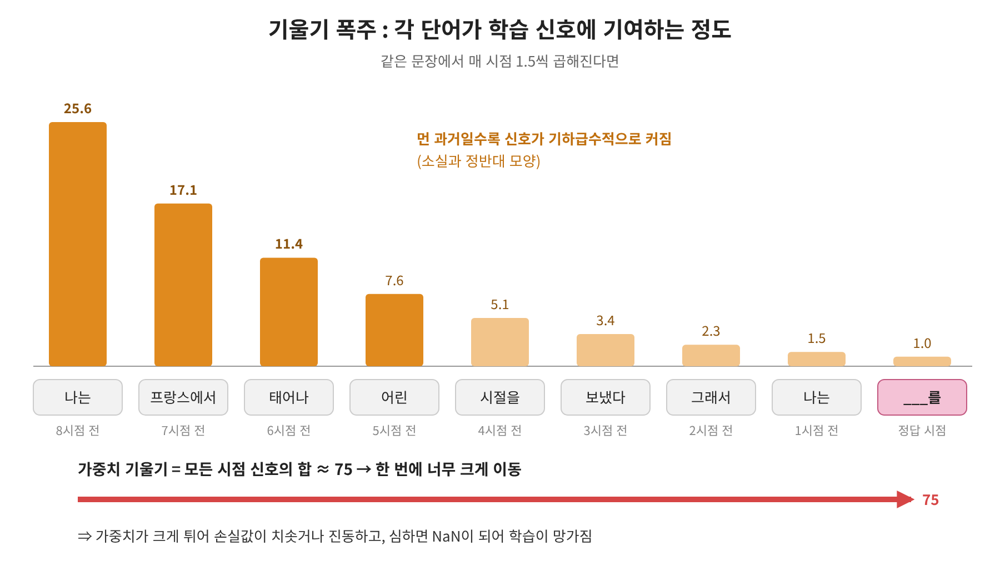
    
**긴 시퀀스일수록 학습이 불안정해져 먼 의존 관계를 안정적으로 배우기 어려움**

4. **느린 훈련 시간**
- RNN은 시점을 하나씩 순서대로만 계산할 수 있어서, 시퀀스가 길수록 학습에 시간이 오래 걸리게 됨
- 특징
    - 시퀀스 길이에 비례해 계산 시간이 늘어남
    - 역전파를 위해 모든 시점의 은닉 상태를 저장해야 해서 메모리 부담도 큼
- CNN과의 차이점
    - CNN : 필터가 각 위치를 독립적으로 계산 -> 여러 위치를 동시에(병렬로) 처리 가능
    - RNN : 앞 시점 결과가 있어야 다음 계산 가능

**시퀀스가 길어질수록 앞부분의 맥락을 뒷부분이 알게 하는 데 많은 학습 비용 들어감**

#### **2. 장기 의존성 문제 (Long-Term Dependency Problem)**
**세 가지 한계의 공통점??**
| 한계 | 무슨 일이 일어나나 | 결과 |
| --- | --- | --- |
| 🌀 기울기 소실 | 먼 과거로 갈수록 학습 신호가 0에 가까워짐 | ❌ 먼 과거 정보 반영 안 됨 |
| 🌋 기울기 폭주 | 먼 과거로 갈수록 신호가 폭발해 학습이 불안정 | ❌ 먼 관계를 안정적으로 학습하지 못함 |
| 🐌 느린 훈련 시간 | 시퀀스가 길어질수록 학습 비용 증가 | ❌ 먼 관계를 학습하기 위해서는 많은 학습비용이 필요 |

**결국 하나의 문제로 귀결된다!** -> **장기 의존성 문제(시퀀스에서 관련된 정보가 멀리 떨어져 있을수록, RNN이 그 관계를 기억하고 학습하지 못하는 문제)**

**여기서 필요한 것!!** : 중요한 정보는 잊지 않고 오래 기억하고, 불필요한 정보는 잊는 메모리 구조 -> **LSTM & GRU**



### **4. 똑똑하게 기억하고 잊는 법 : LSTM & GRU**
#### **4-1. LSTM & GRU**
두 모델 모드 **게이트(gate)** 를 활용해 무엇을 기억하고 무엇을 기억하지 않을지 결정!
- **게이트?** : 정보를 얼마나 통과시킬지 정하는 구성
    - 0~1 사이 값을 정보에 곱함 → 0이면 버림, 1이면 그대로 유지, 0.5면 절반만 반영
    
     ex) [5, 3, 8] ⊙ [1, 0, 0.5] = [5, 0, 4] → 그대로 남김 / 지움 / 절반만 남김
    
    - 값은 현재 입력과 이전 은닉 상태를 보고 모델이 스스로 계산 (sigmoid 사용)
    - **정보를 선택적으로 기억하고 징루 수 있게 됨**

1. **LSTM(Long Short-Term Memory) : 기억을 두 개의 상태로 나눠서 관리**
**두 개의 상태**

| 구분 | 역할 |
| --- | --- |
| 셀 상태 (Cell State, c) | 장기 기억 |
| 은닉 상태 (Hidden State, h) | 단기 기억 & 출력 |

-> 기존 RNN은 **은닉 상태 하나**에 몯느 걸 덮어썼지만, LSTM은 **오래 남길 기억(셀 상태)을 따로 빼둠**

**세 개의 게이트**
1. **Forget Gate**
→ 장기 기억에서 더 이상 필요 없는 내용을 삭제
2. **Input Gate**
→ 새로 들어온 정보 중 중요한 것만 장기기억에 저장
3. **Output Gate**
→ 장기기억 중 지금 필요한 부분만 꺼내 단기기억으로 내보냄

**정리**
- 장기 기억과 단기기억을 **분리해서 관리** -> 정보 정교하게 다룰 수 있음
- 게이트 3개 + 상태 2개 -> **구조가 복잡하고 계산량 많음**

2. **GRU(Gated Recurrent Unit) : 기억을 하나로 통합해서 관리**
**하나로 통합된 상태**
- 셀 상태와 은닉 상태로 나누지 않고, **은닉 상태 $h$ 하나**에 **기억**과 **출력**을 모두 포함

**두 개의 게이트**

1. **Update Gate** -> 과거 기억 : 새 정보 = 몇 : 몇 
→ 예) 과거 70 : 새 정보 30으로 섞기
→ LSTM의 Forget Gate + Input Gate를 게이트 하나로 처리
2. **Reset Gate** -> 과거 기억을 얼마나 무시할건지 
→ 새 정보를 해석할 때 과거 기억을 얼마나 참고할지 결정

**정리**

- 게이트 2개 + 상태 1개 -> LSTM보다 **단순하고 계산이 빠름**
- 대신 기억을 세밀하게 나누지 않아 **정교함은 상대적으로 낮음**

**한눈에 비교**
| 구분 | LSTM | GRU |
| --- | --- | --- |
| 상태 | 셀 상태 + 은닉 상태 (2개) | 은닉 상태 (1개) |
| 게이트 | Forget · Input · Output (3개) | Update · Reset (2개) |
| 핵심 아이디어 | 장기·단기 기억을 분리 | 기억과 출력을 통합 |
| 장점 | 정교한 기억 관리 | 단순하고 빠름 |
| 단점 | 복잡하고 계산량 많음 | 정교함이 떨어짐 |

#### **4.2 게이트(Gate)로 정보의 흐름을 제어하다 : LSTM**
1. **LSTM (Long Short Term Memory) 구조**

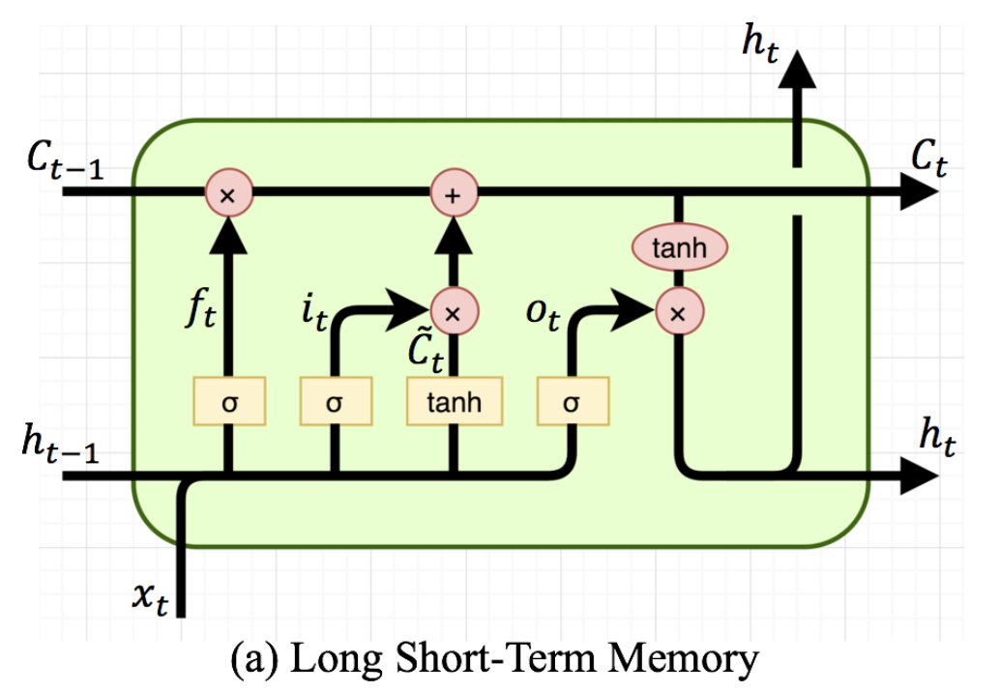

**핵심**

- 셀 상태(Cell State - 장기기억) : 구조도 맨 위를 가로지르는 선 -> 시점을 따라 쭉 이어짐
    - 정보가 큰 변화 없이 타고 다음 시점으로 흘러감
    - 게이트가 정보를 **빼거나(잊기)** **더해서(기억하기)** 조절
    
    -> 기억할 내용과 잊어버릴 내용을 선택해, 중요한 정보를 오래 가져갈 수 있음
    

**RNN과의 주요 차이**

| 구분 | RNN | LSTM |
| --- | --- | --- |
| 순환되는 상태 | 은닉 상태 h (1개) | 셀 상태 C + 은닉 상태 h (2개) |
| 역할 | 기억과 출력을 h 하나가 모두 담당 | c = 장기 기억, h = 단기 기억이자 출력 |
| 기억 갱신 | 매 시점 통째로 덮어씀 | 게이트로 선택적으로 지우고 더함 |

2. **단계별로 알아보는 LSTM 수식**
**공통 표기**
- [hₜ₋₁, xₜ] : 이전 은닉 상태와 현재 입력을 이어 붙인 벡터
- σ : sigmoid (출력 0~1)
    - 1에 가까울수록 많이 기억 / 통과
    - 0에 가까울수록 많이 잊음 / 차단
- ⊙ : 같은 위치끼리 곱하기 (칸별로 게이트 값을 곱함)

**Step 1. Forget gate : "무엇을 잊을까?"**

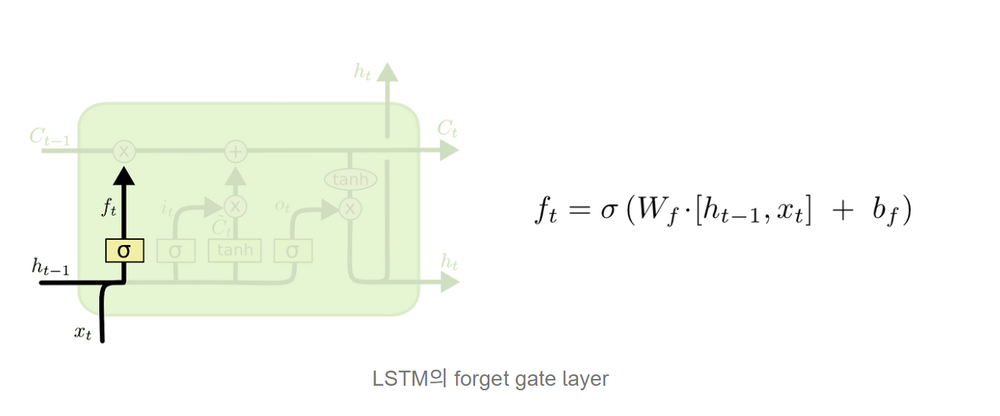

- 이전 셀 상태 $Cₜ₋₁$의 각 칸에 곱해질 0~1 값
- $fₜ ≈ 1$ → 그대로 유지 / $fₜ ≈ 0$ → 완전히 잊음

**Step 2. Input gate : "무엇을 새로 기억할까?"**

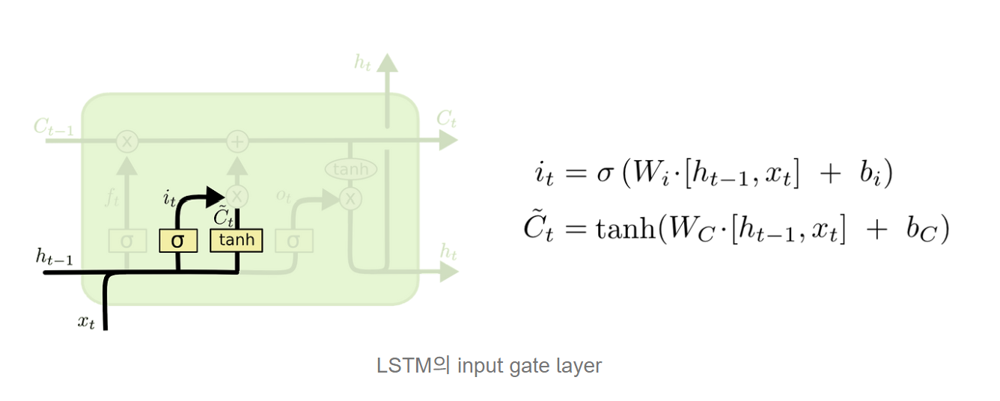

- $iₜ = σ(W_i · [hₜ₋₁, xₜ] + b_i)$ → 새 정보를 얼마나 반영할지 (0~1)
- $C̃ₜ = tanh(W_C · [hₜ₋₁, xₜ] + b_C)$ → 추가할 후보 정보(이번 시점에 새로 기억할 수도 있는 정보의 후보) (-1~1)
- 실제로 더해지는 양 = $iₜ ⊙ C̃ₜ$

**Step 3. Final memory cell : "기억 업데이트"**

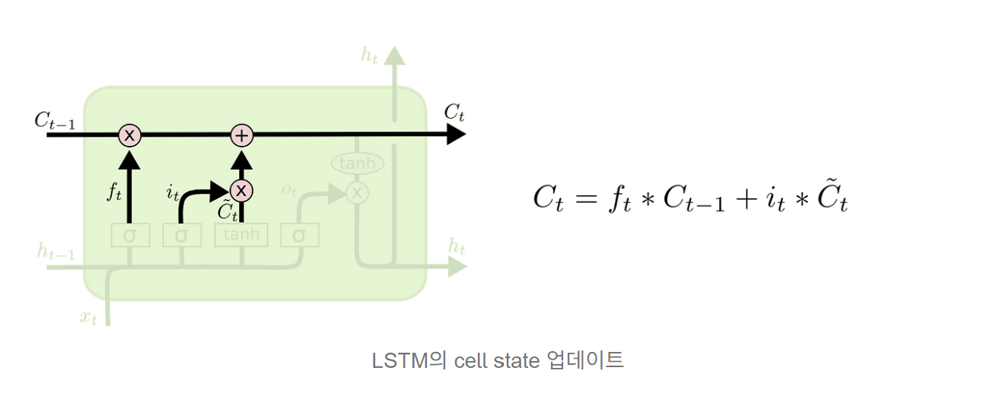

- $Cₜ = fₜ ⊙ Cₜ₋₁ + iₜ ⊙ C̃ₜ$
- Step 1에서 남긴 이전 기억 + Step 2에서 고른 새 정보
- 곱셈이 아닌 덧셈으로 이어지는 핵심 구간

**Step 4. Output gate : "무엇을 내보낼까?"**

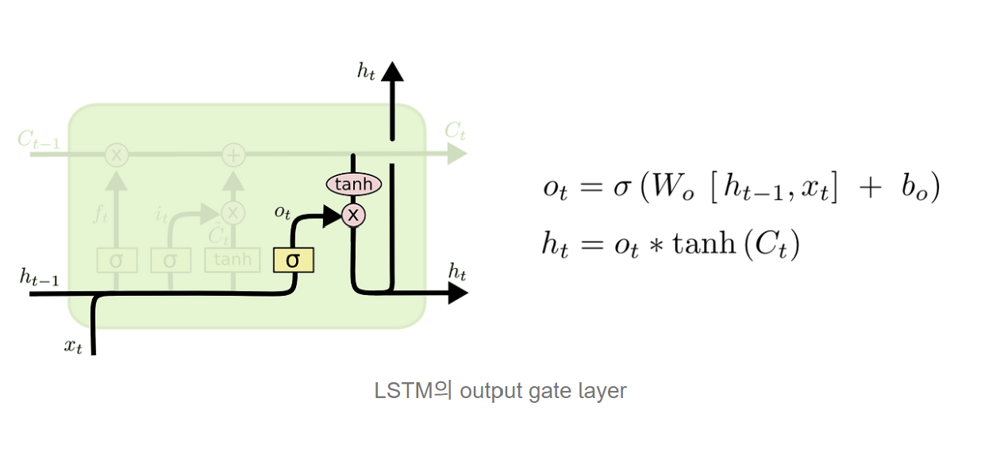

- $oₜ = σ(W_o · [hₜ₋₁, xₜ] + b_o)$ → 셀 상태 중 어느 부분을 내보낼지 (0~1)
- $hₜ = oₜ ⊙ tanh(Cₜ)$ → 셀 상태를 -1~1로 정리한 뒤, 필요한 부분만 출력

3. **LSTM의 장단점**
**장점**
- 셀 상태의 덧셈 구조 덕분에 기울기가 먼 과거까지 전달 -> 기울기 소실 완화
- 게이트로 중요한 정보는 남기고 불필요한 정보는 지움 -> 장기 의존성 학습 가능
- 문장 번역, 음성 인식 등 긴 시퀀스 과제에서 RNN보다 좋은 성능

**단점**
- 계산량이 많아 학습이 느리고 메모리도 많이 사용
- 여전히 시점을 순서대로 계산해야 함 -> 병렬 처리 불가 (느린 훈련 시간 문제는 그대로)
- 기울기 소실을 "완화"한 것이지 완전히 없앤 것은 아님 -> 매우 긴 시퀀스에서는 여전히 한계

=> **더 단순한 구조인 GRU 등장 배경**

#### **4-3. 더 단순하고 효율적인 구조 : GRU (Gated Recurrent Unit)**
1. **GRU(Gated Recurrent Units)의 정의**
- LSTM의 핵심 아이디어(게이트로 정보를 선택적으로 기억·삭제)는 유지하면서, 구조를 단순하게 줄인 모델
    - LSTM : 상태 2개(셀 상태 + 은닉 상태), 게이트 3개
    - GRU : 상태 1개(은닉 상태), 게이트 2개 (LSTM을 더 가볍게 만든 버전)

#### **2. LSTM과의 차이점**

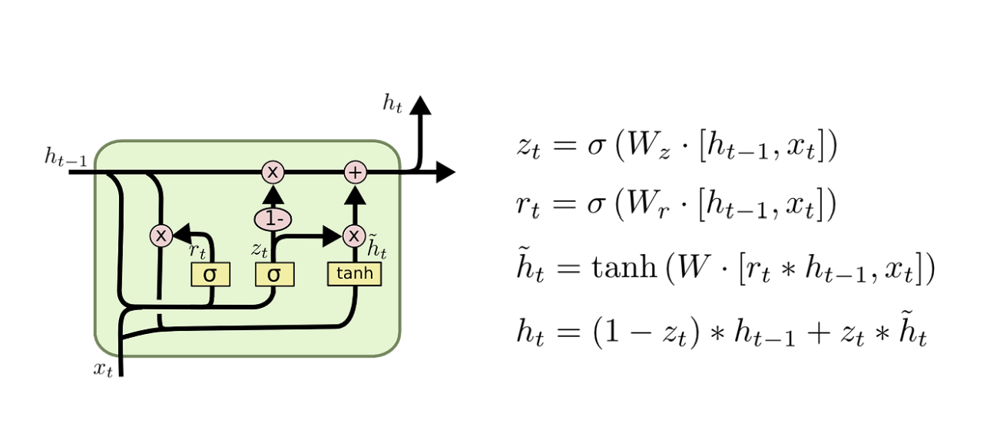

1) **Forget gate와 Input gate를 Update gate 하나로 통합**

- Update gate $zₜ$ 하나로 ‘과거 기억 : 새 정보 = 몇 : 몇’ <u></u>을 한 번에 결정
- $hₜ = (1 − zₜ) ⊙ hₜ₋₁ + zₜ ⊙ h̃ₜ$
- ex) $zₜ$ = 0.3 → 과거 기억 70% + 새 정보 30%

2) **Reset gate를 사용**

- Reset gate $rₜ$로 "과거 기억을 얼마나 무시할지"를 먼저 정한 뒤 후보 정보 $h̃ₜ$를 만듦
- $rₜ$ ≈ 0 → 과거를 거의 무시하고 현재 입력 위주로 새 정보를 만듦
- ex) 문장이 끝나고 새 문장이 시작될 때, 이전 문맥을 끊고 새로 시작

3) **Output gate가 없음**

- 출력을 거르는 단계 없이 은닉 상태 $hₜ$를 그대로 출력

4) **Gate의 개수가 3개에서 2개로 감소**

- 파라미터가 LSTM의 약 3/4 → 계산량이 줄어 학습 시간이 짧아짐
- 그런데도 성능은 LSTM과 비슷하거나, 과제에 따라 더 좋은 경우도 있음

| 구분 | LSTM | GRU |
| --- | --- | --- |
| 기억 상태 | 셀 상태 + 은닉 상태 (2개) | 은닉 상태 (1개) |
| 잊기 / 기억하기 | Forget gate, Input gate 따로 | Update gate 하나로 (몇 대 몇) |
| 과거 무시 여부 | 별도 게이트 없음 | Reset gate |
| 출력 조절 | Output gate | 없음 (은닉 상태 그대로 출력) |
| 게이트 수 | 3개 | 2개 |
| 파라미터 | 많음 | LSTM의 약 3/4 |

#### **3. GRU의 장단점(vs. LSTM)**

| 구분 | 장점 (LSTM 대비) | 단점 (LSTM 대비) |
| --- | --- | --- |
| 구조 | 상태 1개, 게이트 2개로 단순 → 이해·구현이 쉬움 | 장기 기억과 출력을 분리하지 못함 |
| 속도 | 파라미터가 적어 학습이 빠르고 메모리 사용이 적음 | ❎ |
| 데이터 | 파라미터가 적어 데이터가 적을 때도 학습이 안정적 | 데이터가 많고 복잡한 과제에서는 LSTM이 더 나을 수 있음 |
| 기억 관리 | Update gate 하나로 기억 갱신을 간단히 처리 | 잊는 양과 더하는 양을 따로 조절할 수 없어 정교함이 떨어짐 |
| 성능 | 많은 과제에서 LSTM과 비슷한 성능 | 항상 LSTM보다 낫다고 단정할 수는 없음 |

#### **4-4. LSTM vs GRU : 언제 무엇을 선택할까?**

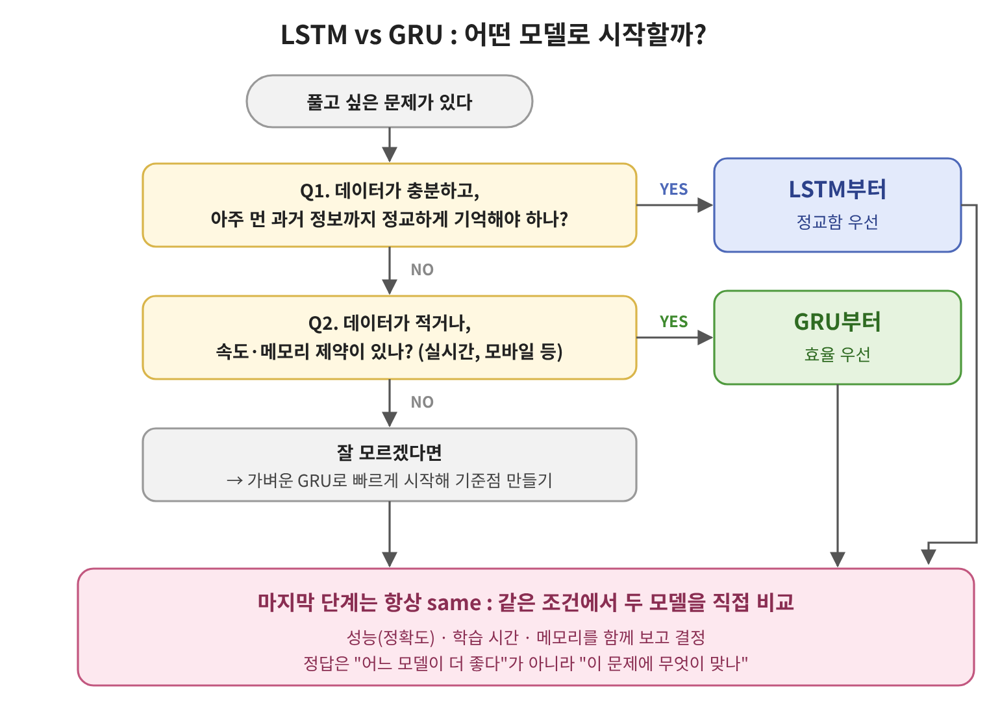

**결론 : 문제 상황에 따라 적합한 모델이 다르다!!**

### **5. 문장을 입력받아 문장을 출력하다 : Seq2Seq**
#### **5-1. Seq2Seq의 기본 구조 : 인코더와 디코더**
**정의**
- **Sequence-to-Sequence** : 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델
- **입력과 출력의 길이가 서로 달라도 됨 -> 기존 RNN과의 가장 큰 차이!!**
    - 예) "I am a student" (4단어) -> "je suis étudiant" (3단어)
    - 번역같은 경우 : 언어마다 어순도 다르고 표현되었을 때 단어 수의 차이도 존재하는데 이때 사용하는게 Seq2Seq
- 앞에서 본 RNN 아키텍처 중 "Many to Many"를 **두 개의 RNN(LSTM)으로 나눠 구현한 구조**
- 활용 분야 : 기계 번역, 챗봇(질문 -> 답변), 문서 요약, 음성 인식

**특징**

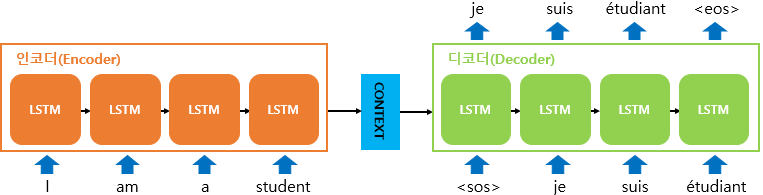

- **인코더(Encoder)**와 **디코더(Decoder)** 두 개의 모듈로 구성
- **인코더** : 입력 문장을 읽고 하나의 **컨텍스트 벡터**로 압축
- **컨텍스트 벡터(Context Vector) :** 인코더와 디코더를 잇는 다리이자 인코더를 거치면서 압축된 정보
- **디코더** : 컨텍스트 벡터를 받아 출력 문장을 한 단어씩 생성
- 내부 셀로는 주로 LSTM 또는 GRU를 사용 -> 앞에서 배운 장기 의존성 문제 때문

**한 줄 요약**
**읽고 (인코더) -> 요약해서 넘기고 (컥텍스트 벡터) -> 다시 써낸다 (디코더)**

#### **1. 인코더**

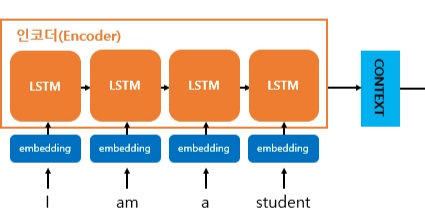

**정의** : 입력 문장의 모든 단어를 순서대로 읽고, 문장 전체의 정보를 하나의 벡터(컨텍스트 벡터)로 압축하는 LSTM

**작동원리**
**1. 단어 토큰화** : 입력 문장을 단어 단위로 나눔 → "I", "am", "a", "student"

**2. 임베딩(embedding)** : 각 단어를 컴퓨터가 계산할 수 있는 숫자 벡터로 변환

**3. LSTM 셀에 한 단어씩 입력** : 매 시점 은닉 상태가 다음 시점으로 전달되며 정보가 누적됨

**4. 마지막 시점의 은닉 상태** = 문장 전체 정보가 담긴 **컨텍스트 벡터** -> 디코더로 전달

**인코더는 중간 시점 출력은 사용하지 않고, 마지막 은닉 상태인 컨벡스트 벡터만 디코더로 넘김.**

#### **2. 디코더 (Decoder)**

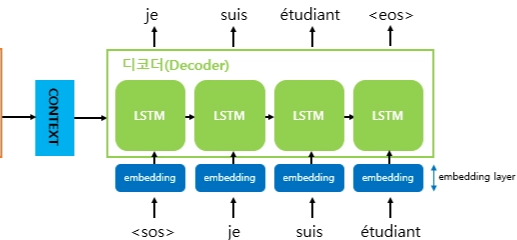

**정의** : 컨텍스트 벡터를 받아, 출력 문장을 한 단어씩 순서대로 생성하는 LSTM

**작동원리**

1. 컨텍스트 벡터를 디코더 LSTM의 첫 은닉 상태로 받음

2. 시작 신호 <sos>(start of sequence)를 첫 입력으로 넣음

3. 매 시점 softmax로 다음 단어의 확률을 계산 -> 가장 확률이 높은 단어 선택(argmax)

4. 방금 예측한 단어를 다음 시점의 입력으로 다시 넣음

ex) <sos> -> "je" -> "suis" -> "étudiant"

5. 종료 신호 <eos>(end of sequence)가 나오면 생성 종료

#### **3. 컨텍스트 벡터(Context Vector)**

**정의** 
- 인코더가 입력 문장 전체를 읽고 만든 문장 요약 벡커
- 인코더 LSTM의 마지막 시점 은닉 상태 (LSTM이면 셀 상태도 함께 넘김)
- 인코더와 디코더를 연결하는 유일 통로

**차원 설정**
- 컨텍스트 벡터의 크기 = 인코더 LSTM의 은닉 상태 크기 (-> 사람이 정하는 하이퍼파라미터)
- 실제로는 보통 수백 차원(256, 512, 1024 등)
- 디코더 LSTM의 은닉 상태 크기도 같은 값으로 맞춰야 바로 이어받을 수 있음
- 차원이 크면? 더 많은 정보 담을 수 있으나 계산량이 늘고 과적합 위험
- 차원이 작으면? 빠르지만 긴 문장의 정보를 다 담지 못함

### **5-2. Seq2Seq의 한계 : 병목 현상 (Bottleneck)**
#### **병목 현상**

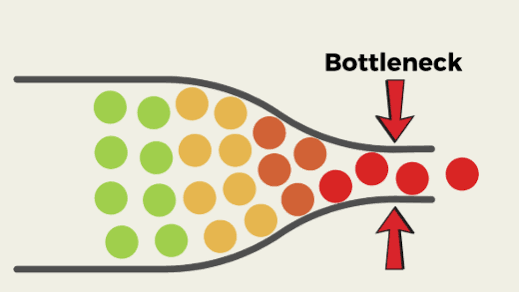

**정의** : 인코더가 입력 문장 전체를 '고정된 크기의 컨텍스트 벡터 하나'에 압축하면서 정보가 좁은 통로에 막혀 손실되는 현상

**설명**

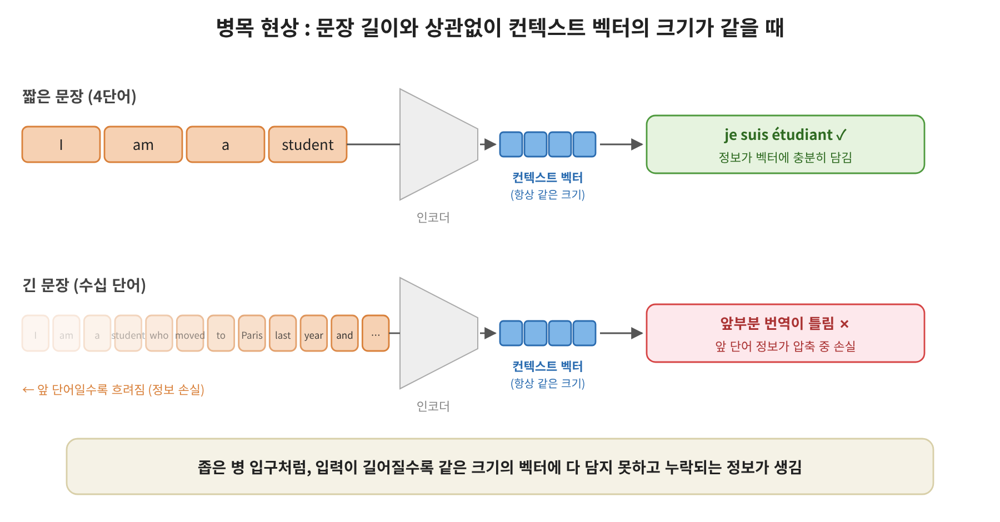

- 5단어든 50단어든 같은 크기(예: 512차원)에 담아야 함
    - 긴 문장일수록 정보를 다 담지 못하고 손실되는 정보 발생
- 앞 단어는 여러 시점을 거치며 희미해짐
    - 장기 의존성 문제 여전히 존재

**예시**
- 짧은 문장 : "I am a student" -> 정보가 적어 컨텍스트 벡터에 충분히 담김 -> 번역 정확
- 긴 문장 : "I am a student who moved to Paris last year and ~" (수십 단어)
    - 같은 크기의 벡터에 담아야 해서 앞부분("I am a student")의 정보가 손실
    - 주어나 앞 내용을 틀리게 번역

**실제 연구에서도 입력 문장이 길어질수록 기본 Seq2Seq의 번역 품질이 급격히 떨어지는 것으로 나타남!!**

#### **결론**
- 고정된 크기의 컨텍스트 벡터에 모든 정보를 압축하기 때문에 병목 현상 발생!
- 특히 긴 입력 시퀀스일수록 정보 손실이 심각하고 모델 성능이 하락!

=> 이러한 한계를 해결한 것 : **Attention!**
